# 03 — Model Explainability and Final Assessment

This notebook investigates the interpretability and explainability of the frozen machine-learning models developed and evaluated in the preceding modelling notebook.

The analysis focuses on understanding how the evaluated models generate churn predictions and on identifying the features that contribute most strongly to predicted customer churn. Intrinsic model interpretability is examined where appropriate, while SHAP-based explainability is applied to compatible model families to provide consistent global and local explanations.

The explainability results are subsequently considered alongside the frozen predictive-performance results to assess which model provides the most appropriate balance between predictive performance and interpretability for telecommunications customer churn prediction.

No model retraining, hyperparameter optimisation or modification is performed in this notebook. All analysis is conducted using the previously frozen model configurations and held-out prepared data.

# 1. Environment Setup and Artefact Paths

The explainability environment is initialised and the persistent project directories created during the preceding notebooks are referenced. The frozen models and prepared modelling datasets are loaded directly from Google Drive so that the explainability workflow remains independent of the runtime state of the model-development notebook.

In [ ]:
# ============================================================
# Cell 1 — Environment Setup and Artefact Paths
# ============================================================

import os
import sys
import json
import warnings

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# Mount Google Drive
# ------------------------------------------------------------

from google.colab import drive

drive.mount(
    "/content/drive"
)


# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT = "/content/drive/MyDrive/7005SCN_Dissertation"

DATA = os.path.join(
    PROJECT,
    "dataset"
)

OUTPUTS = os.path.join(
    PROJECT,
    "outputs"
)

MODELS = os.path.join(
    PROJECT,
    "models"
)

FROZEN_MODELS = os.path.join(
    MODELS,
    "frozen_final_models"
)


# ------------------------------------------------------------
# Prepared data paths
# ------------------------------------------------------------

TRAIN_TREE_PATH = os.path.join(
    OUTPUTS,
    "train_tree_features"
)

TEST_TREE_PATH = os.path.join(
    OUTPUTS,
    "test_tree_features"
)

TRAIN_LR_PATH = os.path.join(
    OUTPUTS,
    "train_lr_features"
)

TEST_LR_PATH = os.path.join(
    OUTPUTS,
    "test_lr_features"
)


# ------------------------------------------------------------
# Frozen model paths
# ------------------------------------------------------------

LR_MODEL_PATH = os.path.join(
    FROZEN_MODELS,
    "logistic_regression_imbalance_aware"
)

DT_MODEL_PATH = os.path.join(
    FROZEN_MODELS,
    "decision_tree_imbalance_aware"
)

RF_MODEL_PATH = os.path.join(
    FROZEN_MODELS,
    "random_forest_imbalance_aware"
)

XGB_MODEL_PATH = os.path.join(
    FROZEN_MODELS,
    "xgboost_imbalance_aware"
)

LGBM_MODEL_PATH = os.path.join(
    FROZEN_MODELS,
    "lightgbm_imbalance_aware.joblib"
)


# ------------------------------------------------------------
# Basic path validation
# ------------------------------------------------------------

required_paths = {
    "Project directory": PROJECT,
    "Outputs directory": OUTPUTS,
    "Frozen models directory": FROZEN_MODELS,
    "Tree training data": TRAIN_TREE_PATH,
    "Tree test data": TEST_TREE_PATH,
    "LR training data": TRAIN_LR_PATH,
    "LR test data": TEST_LR_PATH,
    "Logistic Regression model": LR_MODEL_PATH,
    "Decision Tree model": DT_MODEL_PATH,
    "Random Forest model": RF_MODEL_PATH,
    "XGBoost model": XGB_MODEL_PATH,
    "LightGBM model": LGBM_MODEL_PATH
}


print("=== Explainability Environment Setup ===\n")

all_paths_valid = True

for name, path in required_paths.items():

    exists = os.path.exists(path)

    all_paths_valid = (
        all_paths_valid
        and exists
    )

    print(
        f"{name:<30}: "
        f"{'Found' if exists else 'MISSING'}"
    )


assert all_paths_valid

print(
    "\nALL_REQUIRED_ARTEFACT_PATHS_VALID:",
    all_paths_valid
)

print(
    "\nNotebook 3 environment initialised successfully."
)

Mounted at /content/drive
=== Explainability Environment Setup ===

Project directory             : Found
Outputs directory             : Found
Frozen models directory       : Found
Tree training data            : Found
Tree test data                : Found
LR training data              : Found
LR test data                  : Found
Logistic Regression model     : Found
Decision Tree model           : Found
Random Forest model           : Found
XGBoost model                 : Found
LightGBM model                : Found

ALL_REQUIRED_ARTEFACT_PATHS_VALID: True

Notebook 3 environment initialised successfully.


## 1.1 Spark Initialisation and Prepared Dataset Loading

A PySpark session is initialised to load the prepared feature datasets generated during data preprocessing. The Logistic Regression representation contains scaled numerical features, while the tree-based representation retains unscaled numerical features.

Both training and held-out test datasets are loaded because training data may be used as a reference or background distribution during explainability analysis, while the held-out test data provide unseen observations for model explanation. No preprocessing pipeline is refitted in this notebook.

In [ ]:
# ============================================================
# Cell 2 — Initialise Spark and Load Prepared Datasets
# ============================================================

from pyspark.sql import SparkSession
from pyspark.ml.linalg import VectorUDT


# ------------------------------------------------------------
# Initialise Spark
# ------------------------------------------------------------

spark = (
    SparkSession.builder
    .appName("TelecomChurn_Explainability")
    .master("local[*]")
    .config("spark.driver.memory", "8g")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")


print("=== Spark Environment ===\n")
print("Spark version :", spark.version)
print(
    "AQE enabled   :",
    spark.conf.get("spark.sql.adaptive.enabled")
)


# ------------------------------------------------------------
# Load prepared datasets
# ------------------------------------------------------------

train_tree = (
    spark.read
    .parquet(TRAIN_TREE_PATH)
    .cache()
)

test_tree = (
    spark.read
    .parquet(TEST_TREE_PATH)
    .cache()
)

train_lr = (
    spark.read
    .parquet(TRAIN_LR_PATH)
    .cache()
)

test_lr = (
    spark.read
    .parquet(TEST_LR_PATH)
    .cache()
)


# ------------------------------------------------------------
# Materialise and validate row counts
# ------------------------------------------------------------

dataset_counts = {
    "Tree train": train_tree.count(),
    "Tree test": test_tree.count(),
    "LR train": train_lr.count(),
    "LR test": test_lr.count()
}


print("\n=== Prepared Dataset Validation ===\n")

for name, count in dataset_counts.items():
    print(
        f"{name:<15}: "
        f"{count:,} rows"
    )


# Expected frozen split from Notebook 1
assert dataset_counts["Tree train"] == 6762
assert dataset_counts["Tree test"] == 1691
assert dataset_counts["LR train"] == 6762
assert dataset_counts["LR test"] == 1691


# ------------------------------------------------------------
# Validate required modelling columns
# ------------------------------------------------------------

assert "features_unscaled" in train_tree.columns
assert "features_unscaled" in test_tree.columns

assert "features_scaled" in train_lr.columns
assert "features_scaled" in test_lr.columns

assert "label" in train_tree.columns
assert "label" in test_tree.columns
assert "label" in train_lr.columns
assert "label" in test_lr.columns


# ------------------------------------------------------------
# Validate feature-vector dimensions
# ------------------------------------------------------------

tree_feature_count = len(
    train_tree
    .select("features_unscaled")
    .first()["features_unscaled"]
)

lr_feature_count = len(
    train_lr
    .select("features_scaled")
    .first()["features_scaled"]
)


print("\n=== Feature Representation ===\n")

print(
    "Tree feature vector :",
    tree_feature_count,
    "features"
)

print(
    "LR feature vector   :",
    lr_feature_count,
    "features"
)


assert tree_feature_count == 24
assert lr_feature_count == 24


# ------------------------------------------------------------
# Validate held-out churn distribution
# ------------------------------------------------------------

test_distribution = {
    float(row["label"]): int(row["count"])
    for row in (
        test_tree
        .groupBy("label")
        .count()
        .collect()
    )
}


print("\n=== Held-Out Test Distribution ===\n")

print(
    "Non-churn (0):",
    test_distribution.get(0.0, 0)
)

print(
    "Churn (1)    :",
    test_distribution.get(1.0, 0)
)


assert test_distribution.get(0.0) == 1581
assert test_distribution.get(1.0) == 110


print(
    "\nPREPARED_DATASETS_VALID: True"
)

print(
    "\nPrepared datasets loaded successfully "
    "without refitting preprocessing."
)

=== Spark Environment ===

Spark version : 4.0.4
AQE enabled   : true

=== Prepared Dataset Validation ===

Tree train     : 6,762 rows
Tree test      : 1,691 rows
LR train       : 6,762 rows
LR test        : 1,691 rows

=== Feature Representation ===

Tree feature vector : 24 features
LR feature vector   : 24 features

=== Held-Out Test Distribution ===

Non-churn (0): 1581
Churn (1)    : 110

PREPARED_DATASETS_VALID: True

Prepared datasets loaded successfully without refitting preprocessing.


## 1.2 Feature-Name Recovery and Validation

The modelling feature names generated during preprocessing are recovered and aligned with the 24-dimensional feature vectors used by the frozen models. Preserving the original encoded feature names is essential for interpretable coefficient analysis and SHAP visualisations.

The feature order is validated before any explainability analysis is performed so that each model contribution can be attributed to the correct customer characteristic.

In [ ]:
# ============================================================
# Cell 3 — Recover, Validate and Persist Feature Names
# ============================================================

import os
import json
import pandas as pd


# ------------------------------------------------------------
# Attempt 1: recover names from Spark vector metadata
# ------------------------------------------------------------

def extract_vector_feature_names(df, vector_col):

    metadata = df.schema[vector_col].metadata

    try:
        attrs = metadata["ml_attr"]["attrs"]

        feature_entries = []

        for attr_group in attrs.values():
            feature_entries.extend(attr_group)

        feature_entries = sorted(
            feature_entries,
            key=lambda x: x["idx"]
        )

        names = [
            entry["name"]
            for entry in feature_entries
        ]

        return names

    except Exception:
        return None


feature_names = extract_vector_feature_names(
    train_tree,
    "features_unscaled"
)


print("=== Feature-Name Recovery ===\n")


# ------------------------------------------------------------
# Attempt 2: use the exact feature order established
# during Notebook 1 preprocessing
# ------------------------------------------------------------

if feature_names is None or len(feature_names) != 24:

    print(
        "Spark vector metadata did not contain "
        "the complete readable feature mapping."
    )

    print(
        "Using the validated feature order "
        "established during Notebook 1 preprocessing.\n"
    )

    feature_names = [

        # CRM_PID_Value_Segment one-hot features
        "CRM_PID_Value_Segment_Bronze",
        "CRM_PID_Value_Segment_Silver",
        "CRM_PID_Value_Segment_Gold",
        "CRM_PID_Value_Segment_Platinum",
        "CRM_PID_Value_Segment_SME",
        "CRM_PID_Value_Segment_Iron",
        "CRM_PID_Value_Segment_SE",
        "CRM_PID_Value_Segment_Lead",
        "CRM_PID_Value_Segment_Unknown",
        "CRM_PID_Value_Segment___unknown",

        # EffectiveSegment one-hot features
        "EffectiveSegment_SOHO",
        "EffectiveSegment_VSE",
        "EffectiveSegment_SME",
        "EffectiveSegment_SE",
        "EffectiveSegment_Other",
        "EffectiveSegment_LE",
        "EffectiveSegment___unknown",

        # Numerical features
        "Active_subscribers",
        "Not_Active_subscribers",
        "Suspended_subscribers",
        "AvgMobileRevenue",
        "AvgFIXRevenue",
        "ARPU",
        "Inactive_Ratio"
    ]

else:

    print(
        "Feature names successfully recovered "
        "from Spark vector metadata.\n"
    )


# ------------------------------------------------------------
# Validate dimensions
# ------------------------------------------------------------

assert len(feature_names) == 24
assert len(feature_names) == tree_feature_count
assert len(feature_names) == lr_feature_count

assert len(set(feature_names)) == 24


# ------------------------------------------------------------
# Display ordered feature mapping
# ------------------------------------------------------------

feature_name_df = pd.DataFrame(
    {
        "Feature Index": range(24),
        "Feature Name": feature_names
    }
)


print("=== Ordered Model Features ===\n")

display(feature_name_df)


# ------------------------------------------------------------
# Persist mapping for future notebooks / reproducibility
# ------------------------------------------------------------

FEATURE_NAMES_PATH = os.path.join(
    OUTPUTS,
    "feature_names_explainability.json"
)

with open(
    FEATURE_NAMES_PATH,
    "w"
) as f:

    json.dump(
        feature_names,
        f,
        indent=4
    )


# ------------------------------------------------------------
# Verify saved mapping
# ------------------------------------------------------------

assert os.path.exists(
    FEATURE_NAMES_PATH
)

with open(
    FEATURE_NAMES_PATH,
    "r"
) as f:

    feature_names_check = json.load(f)

assert feature_names_check == feature_names


print(
    "\nRecovered feature names :",
    len(feature_names)
)

print(
    "Tree vector dimensions  :",
    tree_feature_count
)

print(
    "LR vector dimensions    :",
    lr_feature_count
)

print(
    "\nSaved feature mapping:"
)

print(
    FEATURE_NAMES_PATH
)

print(
    "\nFEATURE_NAMES_VALID: True"
)

=== Feature-Name Recovery ===

Feature names successfully recovered from Spark vector metadata.

=== Ordered Model Features ===



,Feature Index,Feature Name
0,0,CRM_PID_Value_Segment_OHE_Bronze
1,1,CRM_PID_Value_Segment_OHE_Silver
2,2,CRM_PID_Value_Segment_OHE_Gold
3,3,CRM_PID_Value_Segment_OHE_Platinum
4,4,CRM_PID_Value_Segment_OHE_SME
5,5,CRM_PID_Value_Segment_OHE_Iron
6,6,CRM_PID_Value_Segment_OHE_SE
7,7,CRM_PID_Value_Segment_OHE_Lead
8,8,CRM_PID_Value_Segment_OHE_Unknown
9,9,CRM_PID_Value_Segment_OHE___unknown



Recovered feature names : 24
Tree vector dimensions  : 24
LR vector dimensions    : 24

Saved feature mapping:
/content/drive/MyDrive/7005SCN_Dissertation/outputs/feature_names_explainability.json

FEATURE_NAMES_VALID: True


## 1.3 Frozen Model Loading and Validation

The five imbalance-aware model configurations persisted following model development are loaded directly from their saved artefacts. This ensures that the explainability analysis examines exactly the same fitted models used during the final predictive evaluation.

No model fitting or hyperparameter optimisation is performed during this stage. The loaded models are validated against the expected 24-feature representation before interpretability and SHAP analysis begins.

In [ ]:
# ============================================================
# Cell 4 — Load and Validate Frozen Models
# ============================================================

import os
import joblib

from pyspark.ml.classification import (
    LogisticRegressionModel,
    DecisionTreeClassificationModel,
    RandomForestClassificationModel
)


# ------------------------------------------------------------
# XGBoost Spark model import
# ------------------------------------------------------------

try:
    from xgboost.spark import SparkXGBClassifierModel

    xgb_spark_available = True

except Exception as e:

    xgb_spark_available = False

    raise ImportError(
        "SparkXGBClassifierModel could not be imported."
    ) from e


print("=== Frozen Model Loading ===\n")


# ------------------------------------------------------------
# Load PySpark models
# ------------------------------------------------------------

lr_frozen_model = (
    LogisticRegressionModel.load(
        LR_MODEL_PATH
    )
)

print("Logistic Regression : Loaded")


dt_frozen_model = (
    DecisionTreeClassificationModel.load(
        DT_MODEL_PATH
    )
)

print("Decision Tree       : Loaded")


rf_frozen_model = (
    RandomForestClassificationModel.load(
        RF_MODEL_PATH
    )
)

print("Random Forest       : Loaded")


# ------------------------------------------------------------
# Load Spark XGBoost model
# ------------------------------------------------------------

xgb_frozen_model = (
    SparkXGBClassifierModel.load(
        XGB_MODEL_PATH
    )
)

print("XGBoost             : Loaded")


# ------------------------------------------------------------
# Load Python LightGBM model
# ------------------------------------------------------------

lgbm_frozen_model = joblib.load(
    LGBM_MODEL_PATH
)

print("LightGBM            : Loaded")


# ------------------------------------------------------------
# Basic model validation
# ------------------------------------------------------------

print("\n=== Frozen Model Validation ===\n")

print(
    "LR coefficients     :",
    len(lr_frozen_model.coefficients)
)

print(
    "DT feature count    :",
    dt_frozen_model.numFeatures
)

print(
    "RF feature count    :",
    rf_frozen_model.numFeatures
)


# XGBoost feature count may be available through
# the underlying booster rather than Spark model metadata.
xgb_booster = (
    xgb_frozen_model
    .get_booster()
)

xgb_num_features = (
    xgb_booster.num_features()
)

print(
    "XGBoost feature count:",
    xgb_num_features
)


# LightGBM
lgbm_num_features = (
    lgbm_frozen_model.n_features_in_
)

print(
    "LightGBM feature count:",
    lgbm_num_features
)


# ------------------------------------------------------------
# Validate all models against the same 24-feature representation
# ------------------------------------------------------------

assert len(lr_frozen_model.coefficients) == 24
assert dt_frozen_model.numFeatures == 24
assert rf_frozen_model.numFeatures == 24
assert xgb_num_features == 24
assert lgbm_num_features == 24

assert len(feature_names) == 24


print(
    "\nALL_FROZEN_MODELS_LOADED: True"
)

print(
    "\nAll five persisted models are available "
    "for independent explainability analysis."
)

=== Frozen Model Loading ===

Logistic Regression : Loaded
Decision Tree       : Loaded
Random Forest       : Loaded
XGBoost             : Loaded
LightGBM            : Loaded

=== Frozen Model Validation ===

LR coefficients     : 24
DT feature count    : 24
RF feature count    : 24
XGBoost feature count: 24
LightGBM feature count: 24

ALL_FROZEN_MODELS_LOADED: True

All five persisted models are available for independent explainability analysis.


# 2. Logistic Regression Intrinsic Interpretability

Logistic Regression provides intrinsic interpretability through its fitted coefficients. Each coefficient represents the direction and magnitude of the association between a model input and the log-odds of predicted churn, conditional on the remaining features.

Positive coefficients increase the model's predicted log-odds of churn, while negative coefficients decrease them. Because the numerical predictors were standardised prior to Logistic Regression training, their coefficient magnitudes are more directly comparable within the fitted model. One-hot encoded categorical coefficients represent the effect of individual encoded categories relative to the omitted reference category.

Coefficient interpretation describes associations learned by the predictive model and should not be interpreted as evidence of causality.

In [ ]:
# ============================================================
# Cell 5 — Logistic Regression Coefficient Analysis
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Human-readable display names
# ------------------------------------------------------------

feature_names_display = [
    "CRM Value Segment: Bronze",
    "CRM Value Segment: Silver",
    "CRM Value Segment: Gold",
    "CRM Value Segment: Platinum",
    "CRM Value Segment: SME",
    "CRM Value Segment: Iron",
    "CRM Value Segment: SE",
    "CRM Value Segment: Lead",
    "CRM Value Segment: Unknown",
    "CRM Value Segment: Unseen category",

    "Effective Segment: SOHO",
    "Effective Segment: VSE",
    "Effective Segment: SME",
    "Effective Segment: SE",
    "Effective Segment: Other",
    "Effective Segment: LE",
    "Effective Segment: Unseen category",

    "Active Subscribers",
    "Inactive Subscribers",
    "Suspended Subscribers",
    "Average Mobile Revenue",
    "Average Fixed Revenue",
    "ARPU",
    "Inactive Subscriber Ratio"
]


# ------------------------------------------------------------
# Validate display-name alignment
# ------------------------------------------------------------

assert len(feature_names_display) == 24
assert len(feature_names) == 24

feature_name_mapping_df = pd.DataFrame({
    "Feature Index": range(24),
    "Technical Name": feature_names,
    "Display Name": feature_names_display
})


print("=== Feature Display-Name Mapping ===\n")

display(feature_name_mapping_df)


# ------------------------------------------------------------
# Extract frozen Logistic Regression coefficients
# ------------------------------------------------------------

lr_coefficients = np.array(
    lr_frozen_model.coefficients
)

lr_intercept = float(
    lr_frozen_model.intercept
)


assert len(lr_coefficients) == 24


# ------------------------------------------------------------
# Construct coefficient table
# ------------------------------------------------------------

lr_coefficient_df = pd.DataFrame({
    "Feature Index": range(24),
    "Technical Feature": feature_names,
    "Feature": feature_names_display,
    "Coefficient": lr_coefficients
})

lr_coefficient_df["Absolute Coefficient"] = (
    lr_coefficient_df["Coefficient"].abs()
)

lr_coefficient_df["Direction"] = np.where(
    lr_coefficient_df["Coefficient"] > 0,
    "Higher predicted churn",
    np.where(
        lr_coefficient_df["Coefficient"] < 0,
        "Lower predicted churn",
        "No directional effect"
    )
)


# ------------------------------------------------------------
# Rank by absolute coefficient magnitude
# ------------------------------------------------------------

lr_coefficient_ranked_df = (
    lr_coefficient_df
    .sort_values(
        "Absolute Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n=== Logistic Regression Model Summary ===\n")

print(
    f"Intercept: {lr_intercept:.6f}"
)

print(
    f"Number of coefficients: "
    f"{len(lr_coefficients)}"
)


print(
    "\n=== Logistic Regression Coefficients "
    "Ranked by Absolute Magnitude ===\n"
)

display(
    lr_coefficient_ranked_df[
        [
            "Feature",
            "Coefficient",
            "Absolute Coefficient",
            "Direction"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# Directional summaries
# ------------------------------------------------------------

positive_features = (
    lr_coefficient_df[
        lr_coefficient_df["Coefficient"] > 0
    ]
    .sort_values(
        "Coefficient",
        ascending=False
    )
)

negative_features = (
    lr_coefficient_df[
        lr_coefficient_df["Coefficient"] < 0
    ]
    .sort_values(
        "Coefficient",
        ascending=True
    )
)


print(
    "\n=== Strongest Positive Churn Associations ===\n"
)

display(
    positive_features[
        [
            "Feature",
            "Coefficient"
        ]
    ]
    .head(10)
    .round(6)
)


print(
    "\n=== Strongest Negative Churn Associations ===\n"
)

display(
    negative_features[
        [
            "Feature",
            "Coefficient"
        ]
    ]
    .head(10)
    .round(6)
)


print(
    "\nLR_INTRINSIC_INTERPRETABILITY_VALID: True"
)

=== Feature Display-Name Mapping ===



,Feature Index,Technical Name,Display Name
0,0,CRM_PID_Value_Segment_OHE_Bronze,CRM Value Segment: Bronze
1,1,CRM_PID_Value_Segment_OHE_Silver,CRM Value Segment: Silver
2,2,CRM_PID_Value_Segment_OHE_Gold,CRM Value Segment: Gold
3,3,CRM_PID_Value_Segment_OHE_Platinum,CRM Value Segment: Platinum
4,4,CRM_PID_Value_Segment_OHE_SME,CRM Value Segment: SME
5,5,CRM_PID_Value_Segment_OHE_Iron,CRM Value Segment: Iron
6,6,CRM_PID_Value_Segment_OHE_SE,CRM Value Segment: SE
7,7,CRM_PID_Value_Segment_OHE_Lead,CRM Value Segment: Lead
8,8,CRM_PID_Value_Segment_OHE_Unknown,CRM Value Segment: Unknown
9,9,CRM_PID_Value_Segment_OHE___unknown,CRM Value Segment: Unseen category



=== Logistic Regression Model Summary ===

Intercept: -0.004799
Number of coefficients: 24

=== Logistic Regression Coefficients Ranked by Absolute Magnitude ===



,Feature,Coefficient,Absolute Coefficient,Direction
0,Average Mobile Revenue,0.041945,0.041945,Higher predicted churn
1,CRM Value Segment: Bronze,0.000000,0.000000,No directional effect
2,CRM Value Segment: Gold,0.000000,0.000000,No directional effect
3,CRM Value Segment: Silver,0.000000,0.000000,No directional effect
4,CRM Value Segment: SME,0.000000,0.000000,No directional effect
5,CRM Value Segment: Iron,0.000000,0.000000,No directional effect
6,CRM Value Segment: SE,0.000000,0.000000,No directional effect
7,CRM Value Segment: Platinum,0.000000,0.000000,No directional effect
8,CRM Value Segment: Lead,0.000000,0.000000,No directional effect
9,CRM Value Segment: Unknown,0.000000,0.000000,No directional effect



=== Strongest Positive Churn Associations ===



,Feature,Coefficient
20,Average Mobile Revenue,0.041945



=== Strongest Negative Churn Associations ===



,Feature,Coefficient



LR_INTRINSIC_INTERPRETABILITY_VALID: True


### Logistic Regression Interpretation

The frozen imbalance-aware Logistic Regression model produced a highly sparse coefficient structure. Of the 24 encoded model inputs, only **Average Mobile Revenue** retained a non-zero coefficient (β = 0.041945), while the remaining coefficients were reduced to zero.

The positive coefficient indicates that, within the fitted Logistic Regression model, higher standardised Average Mobile Revenue is associated with an increase in the predicted log-odds of churn, conditional on the model specification. The magnitude should be interpreted within the standardised Logistic Regression feature representation rather than in the original monetary units.

The sparsity of the fitted model is consistent with the selected Elastic Net regularisation (regParam = 0.1, elasticNetParam = 0.5), which incorporates an L1 penalty capable of shrinking coefficients exactly to zero. Consequently, the zero coefficients should not be interpreted as evidence that the corresponding customer characteristics have no relationship with churn; rather, they indicate that these inputs did not retain a non-zero linear contribution under the fitted regularised model.

This produces a particularly simple and intrinsically interpretable model, but its interpretability must subsequently be considered alongside its predictive performance and the richer non-linear relationships potentially captured by the tree-based ensemble models.

## 2.1 Logistic Regression Coefficient Visualisation

The fitted Logistic Regression coefficients are visualised to illustrate the relative magnitude and direction of the retained linear effects. The figure highlights the sparsity of the regularised model and provides a direct visual representation of its intrinsic interpretability.

Coefficient values are shown for the standardised Logistic Regression feature representation. Positive values indicate an increase in predicted churn log-odds, while negative values would indicate a decrease. Zero coefficients represent features whose linear contribution was removed by the fitted regularised model.

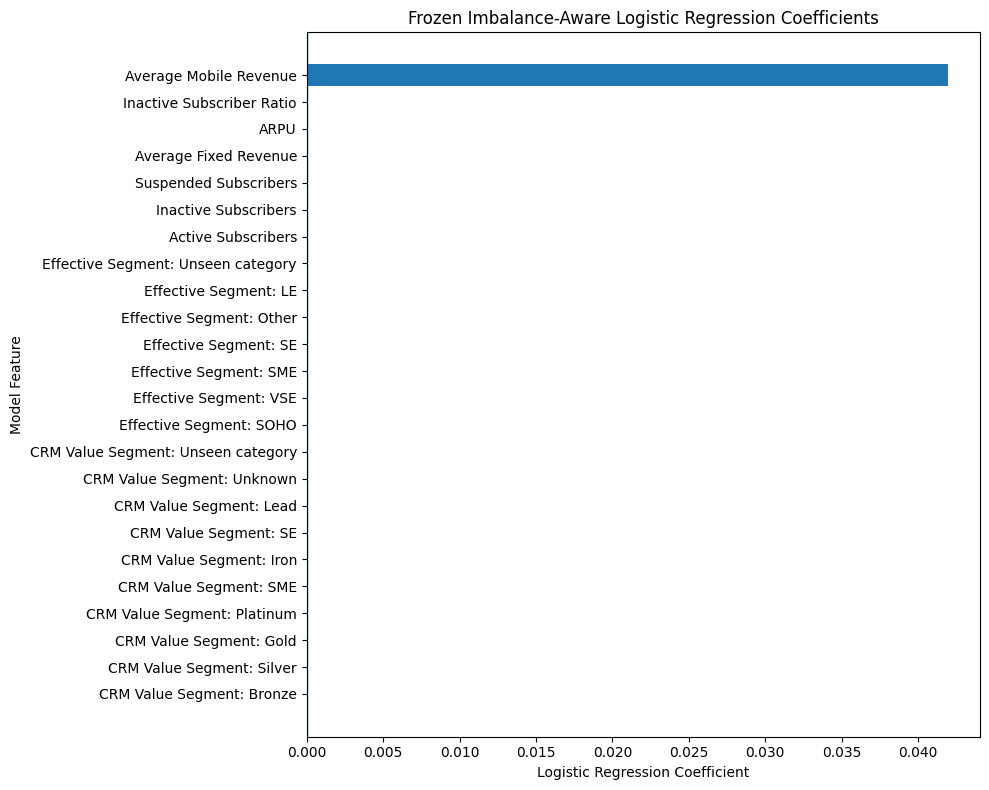


=== Logistic Regression Coefficient Summary ===

Total coefficients    : 24
Non-zero coefficients : 1
Zero coefficients     : 23

Figure saved to:
/content/drive/MyDrive/7005SCN_Dissertation/outputs/lr_coefficient_plot.png

LR_COEFFICIENT_VISUALISATION_VALID: True


In [ ]:
# ============================================================
# Cell 6 — Logistic Regression Coefficient Visualisation
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import os


# ------------------------------------------------------------
# Order coefficients for plotting
# ------------------------------------------------------------

lr_plot_df = (
    lr_coefficient_df
    .sort_values(
        "Coefficient",
        ascending=True
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Create horizontal coefficient plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 8)
)

ax.barh(
    lr_plot_df["Feature"],
    lr_plot_df["Coefficient"]
)

ax.axvline(
    x=0,
    linewidth=1
)

ax.set_xlabel(
    "Logistic Regression Coefficient"
)

ax.set_ylabel(
    "Model Feature"
)

ax.set_title(
    "Frozen Imbalance-Aware Logistic Regression Coefficients"
)

plt.tight_layout()


# ------------------------------------------------------------
# Save dissertation-ready figure
# ------------------------------------------------------------

LR_COEFFICIENT_PLOT_PATH = os.path.join(
    OUTPUTS,
    "lr_coefficient_plot.png"
)

plt.savefig(
    LR_COEFFICIENT_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert os.path.exists(
    LR_COEFFICIENT_PLOT_PATH
)

assert os.path.getsize(
    LR_COEFFICIENT_PLOT_PATH
) > 0


non_zero_count = int(
    np.count_nonzero(
        lr_coefficients
    )
)

zero_count = int(
    len(lr_coefficients)
    - non_zero_count
)


print(
    "\n=== Logistic Regression Coefficient Summary ===\n"
)

print(
    "Total coefficients    :",
    len(lr_coefficients)
)

print(
    "Non-zero coefficients :",
    non_zero_count
)

print(
    "Zero coefficients     :",
    zero_count
)

print(
    "\nFigure saved to:"
)

print(
    LR_COEFFICIENT_PLOT_PATH
)

print(
    "\nLR_COEFFICIENT_VISUALISATION_VALID: True"
)

### Coefficient Visualisation Interpretation

The coefficient visualisation confirms the highly sparse structure of the frozen Logistic Regression model. Only Average Mobile Revenue retained a non-zero coefficient, while the remaining 23 encoded inputs were reduced to zero by the fitted regularisation procedure.

This provides strong intrinsic transparency because the final linear prediction mechanism is extremely simple. However, the limited number of retained effects also suggests that the model represents only a narrow linear relationship within the available predictors. The subsequent SHAP analysis therefore examines whether the non-linear tree-based models capture a broader range of predictive relationships.

## 3.1 SHAP Environment and Explainability Dataset Preparation

The SHAP environment is initialised and the prepared Spark feature vectors are converted into local tabular representations suitable for explainability analysis. The conversion is computationally appropriate because the prepared dataset contains only 24 model inputs and 1,691 held-out test observations.

The original feature-vector order is preserved exactly during conversion and subsequently assigned the validated human-readable feature labels. No transformation, rescaling or refitting is performed during this process.

In [ ]:
# ============================================================
# Cell 7 — SHAP Environment and Explainability Matrices
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap


# ------------------------------------------------------------
# Environment information
# ------------------------------------------------------------

print("=== SHAP Environment ===\n")

print("SHAP version       :", shap.__version__)
print("NumPy version      :", np.__version__)
print("Pandas version     :", pd.__version__)
print("Model feature count:", len(feature_names_display))


# ------------------------------------------------------------
# Helper: Spark vector column -> NumPy matrix
# ------------------------------------------------------------

def spark_vector_to_numpy(df, vector_column):

    rows = (
        df
        .select(vector_column)
        .collect()
    )

    matrix = np.vstack([
        row[vector_column].toArray()
        for row in rows
    ])

    return matrix


# ------------------------------------------------------------
# Tree-model representations
# ------------------------------------------------------------

X_train_tree_np = spark_vector_to_numpy(
    train_tree,
    "features_unscaled"
)

X_test_tree_np = spark_vector_to_numpy(
    test_tree,
    "features_unscaled"
)


# ------------------------------------------------------------
# Logistic Regression representation
# ------------------------------------------------------------

X_train_lr_np = spark_vector_to_numpy(
    train_lr,
    "features_scaled"
)

X_test_lr_np = spark_vector_to_numpy(
    test_lr,
    "features_scaled"
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

y_train = np.array([
    row["label"]
    for row in (
        train_tree
        .select("label")
        .collect()
    )
])

y_test = np.array([
    row["label"]
    for row in (
        test_tree
        .select("label")
        .collect()
    )
])


# ------------------------------------------------------------
# Human-readable pandas representations
# ------------------------------------------------------------

X_train_tree_explain = pd.DataFrame(
    X_train_tree_np,
    columns=feature_names_display
)

X_test_tree_explain = pd.DataFrame(
    X_test_tree_np,
    columns=feature_names_display
)

X_train_lr_explain = pd.DataFrame(
    X_train_lr_np,
    columns=feature_names_display
)

X_test_lr_explain = pd.DataFrame(
    X_test_lr_np,
    columns=feature_names_display
)


# ------------------------------------------------------------
# Validate dimensions
# ------------------------------------------------------------

assert X_train_tree_explain.shape == (6762, 24)
assert X_test_tree_explain.shape == (1691, 24)

assert X_train_lr_explain.shape == (6762, 24)
assert X_test_lr_explain.shape == (1691, 24)

assert len(y_train) == 6762
assert len(y_test) == 1691

assert int(np.sum(y_train == 1.0)) == 439
assert int(np.sum(y_test == 1.0)) == 110


# ------------------------------------------------------------
# Validate that conversion did not introduce missing values
# ------------------------------------------------------------

assert not X_train_tree_explain.isnull().any().any()
assert not X_test_tree_explain.isnull().any().any()

assert not X_train_lr_explain.isnull().any().any()
assert not X_test_lr_explain.isnull().any().any()


# ------------------------------------------------------------
# Check preservation of feature values
# ------------------------------------------------------------

tree_first_original = (
    train_tree
    .select("features_unscaled")
    .first()["features_unscaled"]
    .toArray()
)

lr_first_original = (
    train_lr
    .select("features_scaled")
    .first()["features_scaled"]
    .toArray()
)

assert np.allclose(
    tree_first_original,
    X_train_tree_explain.iloc[0].to_numpy()
)

assert np.allclose(
    lr_first_original,
    X_train_lr_explain.iloc[0].to_numpy()
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n=== Explainability Matrices ===\n")

print(
    "Tree training matrix :",
    X_train_tree_explain.shape
)

print(
    "Tree test matrix     :",
    X_test_tree_explain.shape
)

print(
    "LR training matrix   :",
    X_train_lr_explain.shape
)

print(
    "LR test matrix       :",
    X_test_lr_explain.shape
)


print("\n=== Label Validation ===\n")

print(
    "Training churn cases :",
    int(np.sum(y_train == 1.0))
)

print(
    "Test churn cases     :",
    int(np.sum(y_test == 1.0))
)


print(
    "\nSHAP_DATA_PREPARATION_VALID: True"
)

=== SHAP Environment ===

SHAP version       : 0.52.0
NumPy version      : 2.1.3
Pandas version     : 2.2.3
Model feature count: 24

=== Explainability Matrices ===

Tree training matrix : (6762, 24)
Tree test matrix     : (1691, 24)
LR training matrix   : (6762, 24)
LR test matrix       : (1691, 24)

=== Label Validation ===

Training churn cases : 439
Test churn cases     : 110

SHAP_DATA_PREPARATION_VALID: True


## 3.2 LightGBM SHAP Explainability

SHAP values are calculated for the frozen imbalance-aware LightGBM model using a tree-based explainer. Because LightGBM is a native tree-ensemble implementation, SHAP can efficiently derive feature-attribution values directly from the fitted model structure.

Global feature importance is assessed using the mean absolute SHAP value across the held-out test observations. This measures the average magnitude of each feature's contribution to model output, irrespective of whether that contribution increases or decreases the predicted churn score.

The held-out test data are used only for explanation of the already frozen model; no model fitting, tuning or parameter modification is performed.

In [ ]:
# ============================================================
# Cell 8 — LightGBM SHAP Value Computation
# ============================================================

import shap
import numpy as np
import pandas as pd


print("=== LightGBM SHAP Analysis ===\n")


# ------------------------------------------------------------
# Initialise TreeExplainer using the frozen LightGBM model
# ------------------------------------------------------------

lgbm_explainer = shap.TreeExplainer(
    lgbm_frozen_model
)


# ------------------------------------------------------------
# Calculate SHAP values for held-out test observations
# ------------------------------------------------------------

lgbm_shap_values = lgbm_explainer(
    X_test_tree_explain
)


# ------------------------------------------------------------
# Validate SHAP output
# ------------------------------------------------------------

print(
    "SHAP values shape :",
    lgbm_shap_values.values.shape
)

print(
    "Test matrix shape :",
    X_test_tree_explain.shape
)


assert lgbm_shap_values.values.shape == (
    1691,
    24
)

assert np.isfinite(
    lgbm_shap_values.values
).all()


# ------------------------------------------------------------
# Global mean absolute SHAP importance
# ------------------------------------------------------------

lgbm_mean_abs_shap = np.mean(
    np.abs(
        lgbm_shap_values.values
    ),
    axis=0
)


lgbm_shap_importance_df = pd.DataFrame({
    "Feature": feature_names_display,
    "Mean Absolute SHAP": lgbm_mean_abs_shap
})


lgbm_shap_importance_df = (
    lgbm_shap_importance_df
    .sort_values(
        "Mean Absolute SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n=== LightGBM Global SHAP Importance ===\n"
)

display(
    lgbm_shap_importance_df.round(6)
)


# ------------------------------------------------------------
# Basic SHAP consistency checks
# ------------------------------------------------------------

print(
    "\nBase value sample :",
    np.asarray(
        lgbm_shap_values.base_values
    ).reshape(-1)[0]
)

print(
    "Maximum |SHAP|    :",
    float(
        np.abs(
            lgbm_shap_values.values
        ).max()
    )
)

print(
    "\nLIGHTGBM_SHAP_VALID: True"
)

=== LightGBM SHAP Analysis ===

SHAP values shape : (1691, 24)
Test matrix shape : (1691, 24)

=== LightGBM Global SHAP Importance ===



,Feature,Mean Absolute SHAP
0,Average Mobile Revenue,0.278149
1,ARPU,0.100647
2,Active Subscribers,0.078710
3,Inactive Subscriber Ratio,0.057871
4,Inactive Subscribers,0.035094
5,Average Fixed Revenue,0.017801
6,Effective Segment: SME,0.010180
7,CRM Value Segment: Iron,0.009718
8,CRM Value Segment: Bronze,0.008217
9,CRM Value Segment: SME,0.007321



Base value sample : -0.18328448609749878
Maximum |SHAP|    : 0.9559137386827893

LIGHTGBM_SHAP_VALID: True


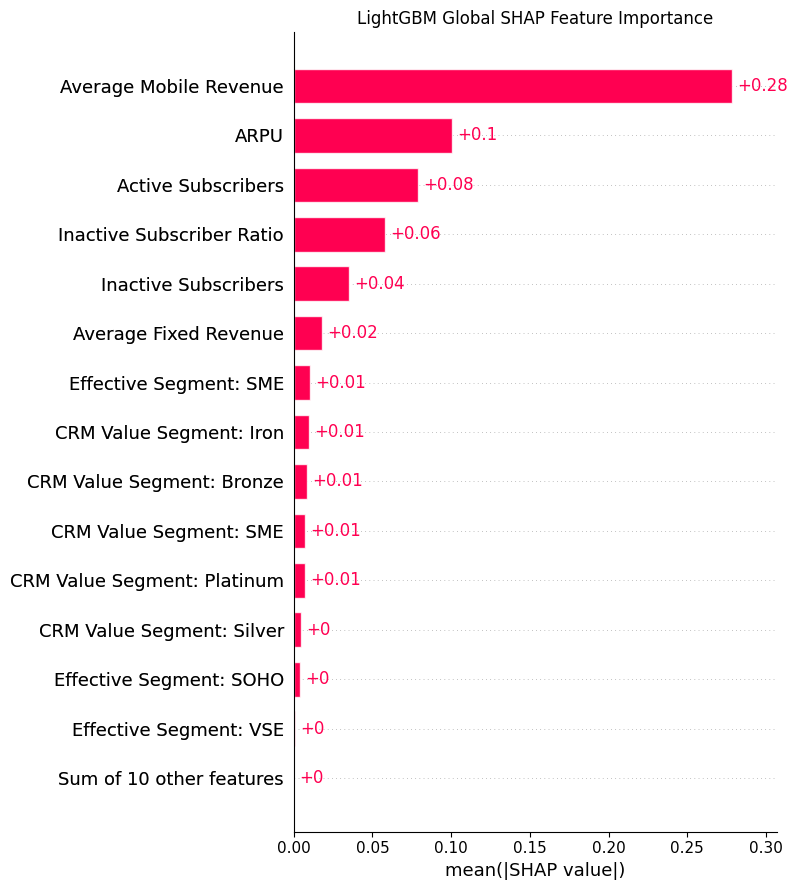

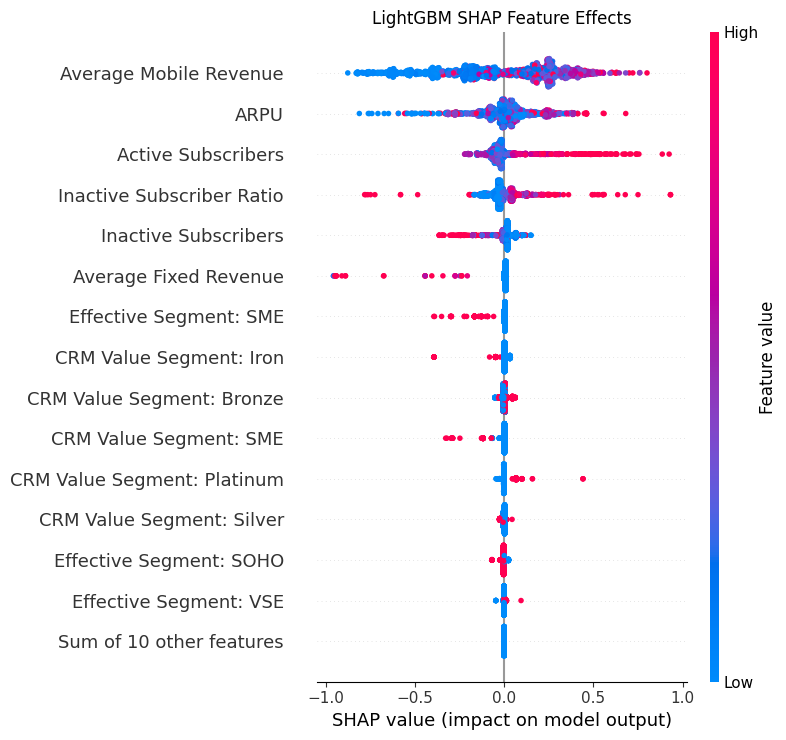


=== LightGBM SHAP Figure Verification ===

Global bar plot : /content/drive/MyDrive/7005SCN_Dissertation/outputs/lightgbm_shap_global_bar.png
Beeswarm plot   : /content/drive/MyDrive/7005SCN_Dissertation/outputs/lightgbm_shap_beeswarm.png

LIGHTGBM_SHAP_VISUALISATIONS_VALID: True


In [ ]:
# ============================================================
# Cell 9 — LightGBM Global SHAP Visualisations
# ============================================================

import os
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Output paths
# ------------------------------------------------------------

LGBM_SHAP_BAR_PATH = os.path.join(
    OUTPUTS,
    "lightgbm_shap_global_bar.png"
)

LGBM_SHAP_BEESWARM_PATH = os.path.join(
    OUTPUTS,
    "lightgbm_shap_beeswarm.png"
)


# ------------------------------------------------------------
# Global SHAP bar plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

shap.plots.bar(
    lgbm_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "LightGBM Global SHAP Feature Importance"
)

plt.tight_layout()

plt.savefig(
    LGBM_SHAP_BAR_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# SHAP beeswarm plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

shap.plots.beeswarm(
    lgbm_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "LightGBM SHAP Feature Effects"
)

plt.tight_layout()

plt.savefig(
    LGBM_SHAP_BEESWARM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Verify saved figures
# ------------------------------------------------------------

assert os.path.exists(
    LGBM_SHAP_BAR_PATH
)

assert os.path.exists(
    LGBM_SHAP_BEESWARM_PATH
)

assert os.path.getsize(
    LGBM_SHAP_BAR_PATH
) > 0

assert os.path.getsize(
    LGBM_SHAP_BEESWARM_PATH
) > 0


print(
    "\n=== LightGBM SHAP Figure Verification ===\n"
)

print(
    "Global bar plot :",
    LGBM_SHAP_BAR_PATH
)

print(
    "Beeswarm plot   :",
    LGBM_SHAP_BEESWARM_PATH
)

print(
    "\nLIGHTGBM_SHAP_VISUALISATIONS_VALID: True"
)

### LightGBM SHAP Interpretation

The global SHAP analysis indicates that **Average Mobile Revenue** is the most influential feature in the frozen LightGBM model, exhibiting a substantially greater mean absolute SHAP value than the remaining predictors. ARPU, Active Subscribers, Inactive Subscriber Ratio and Inactive Subscribers form the next most influential group, while the encoded customer-segment variables generally make smaller contributions to model output.

The SHAP beeswarm plot additionally demonstrates that feature effects are not uniformly linear. Higher values of Average Mobile Revenue and Active Subscribers are frequently associated with positive SHAP contributions, although substantial variation is present across observations. Inactive Subscriber Ratio exhibits contributions in both directions, indicating that its influence depends on the value of the feature and the model's interaction with other predictors. Higher Average Fixed Revenue values are predominantly associated with negative SHAP contributions within the evaluated observations.

These findings contrast with the highly sparse Logistic Regression model, which retained only Average Mobile Revenue as a non-zero linear coefficient. LightGBM therefore captures predictive contributions from a broader range of customer characteristics and allows non-linear and potentially interacting relationships to influence its predictions. This provides richer predictive behaviour but requires post-hoc explanation through SHAP rather than direct interpretation of a simple coefficient structure.

SHAP values describe contributions to the output of the fitted model and should not be interpreted as causal effects.

## 3.3 LightGBM Local SHAP Explanation

In addition to global feature importance, SHAP is used to examine an individual prediction produced by the frozen LightGBM model. A local explanation demonstrates how individual feature values combine to move the model output away from its baseline prediction for a specific customer.

To avoid subjective selection of an observation based on the appearance of its explanation, a deterministic selection rule is applied. From the held-out observations with a true churn label, the customer receiving the highest predicted churn probability from the frozen LightGBM model is selected. The selection therefore represents a strong positive churn prediction for an actual churn case and is determined independently of the resulting SHAP visualisation.

The SHAP waterfall plot decomposes the selected prediction into its baseline model output and the individual feature contributions that move the prediction towards its final model output.

=== Selected LightGBM Local Explanation ===

Selection rule:
Highest predicted churn probability among true churn cases in the held-out test set.

Held-out row index      : 1653
True label              : 1
Predicted class         : 1
Predicted churn probability: 0.717324
SHAP base value         : -0.183284

=== Strongest Local Contributions ===



,Feature,Feature Value,SHAP Value,Absolute SHAP
0,Active Subscribers,26.000000,0.739355,0.739355
1,Average Mobile Revenue,421.170000,0.163927,0.163927
2,Inactive Subscriber Ratio,0.212121,0.106750,0.106750
3,CRM Value Segment: Platinum,1.000000,0.067260,0.067260
4,ARPU,16.200000,0.021412,0.021412
5,Inactive Subscribers,7.000000,0.011655,0.011655
6,CRM Value Segment: Bronze,0.000000,-0.004378,0.004378
7,Average Fixed Revenue,0.000000,0.002461,0.002461
8,CRM Value Segment: Iron,0.000000,0.001831,0.001831
9,Effective Segment: SME,0.000000,0.001768,0.001768


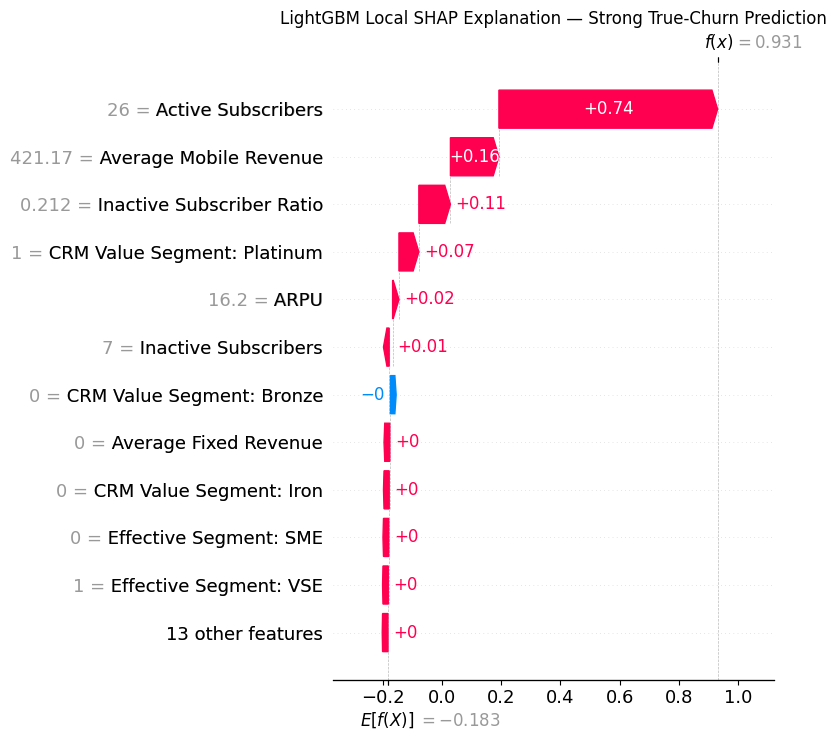


Local SHAP figure saved to:
/content/drive/MyDrive/7005SCN_Dissertation/outputs/lightgbm_shap_local_waterfall.png

LIGHTGBM_LOCAL_SHAP_VALID: True


In [ ]:
# ============================================================
# Cell 10 — LightGBM Local SHAP Explanation
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os


# ------------------------------------------------------------
# Frozen LightGBM probabilities on held-out test data
# ------------------------------------------------------------

lgbm_test_probabilities = (
    lgbm_frozen_model.predict_proba(
        X_test_tree_explain
    )[:, 1]
)


assert len(lgbm_test_probabilities) == len(y_test)
assert np.isfinite(lgbm_test_probabilities).all()


# ------------------------------------------------------------
# Deterministic observation selection
#
# Rule:
# Among TRUE churn observations in the held-out test set,
# select the case receiving the highest predicted churn
# probability from the frozen LightGBM model.
# ------------------------------------------------------------

true_churn_indices = np.where(
    y_test == 1.0
)[0]

assert len(true_churn_indices) == 110


selected_index = true_churn_indices[
    np.argmax(
        lgbm_test_probabilities[
            true_churn_indices
        ]
    )
]


selected_probability = float(
    lgbm_test_probabilities[
        selected_index
    ]
)

selected_prediction = int(
    selected_probability >= 0.5
)

selected_true_label = int(
    y_test[selected_index]
)


# ------------------------------------------------------------
# Retrieve corresponding SHAP explanation
# ------------------------------------------------------------

selected_explanation = (
    lgbm_shap_values[
        selected_index
    ]
)


# ------------------------------------------------------------
# Print case information
# ------------------------------------------------------------

print(
    "=== Selected LightGBM Local Explanation ===\n"
)

print(
    "Selection rule:"
)

print(
    "Highest predicted churn probability "
    "among true churn cases in the held-out test set."
)

print(
    "\nHeld-out row index      :",
    int(selected_index)
)

print(
    "True label              :",
    selected_true_label
)

print(
    "Predicted class         :",
    selected_prediction
)

print(
    "Predicted churn probability:",
    round(
        selected_probability,
        6
    )
)

print(
    "SHAP base value         :",
    round(
        float(
            np.asarray(
                selected_explanation.base_values
            ).reshape(-1)[0]
        ),
        6
    )
)


# ------------------------------------------------------------
# Show strongest local SHAP contributions numerically
# ------------------------------------------------------------

local_contribution_df = (
    pd.DataFrame({
        "Feature":
            feature_names_display,

        "Feature Value":
            X_test_tree_explain
            .iloc[selected_index]
            .to_numpy(),

        "SHAP Value":
            selected_explanation.values
    })
)

local_contribution_df[
    "Absolute SHAP"
] = (
    local_contribution_df[
        "SHAP Value"
    ].abs()
)

local_contribution_df = (
    local_contribution_df
    .sort_values(
        "Absolute SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n=== Strongest Local Contributions ===\n"
)

display(
    local_contribution_df[
        [
            "Feature",
            "Feature Value",
            "SHAP Value",
            "Absolute SHAP"
        ]
    ]
    .head(10)
    .round(6)
)


# ------------------------------------------------------------
# SHAP waterfall plot
# ------------------------------------------------------------

LGBM_LOCAL_SHAP_PATH = os.path.join(
    OUTPUTS,
    "lightgbm_shap_local_waterfall.png"
)


plt.figure(
    figsize=(10, 8)
)

shap.plots.waterfall(
    selected_explanation,
    max_display=12,
    show=False
)

plt.title(
    "LightGBM Local SHAP Explanation — "
    "Strong True-Churn Prediction"
)

plt.tight_layout()

plt.savefig(
    LGBM_LOCAL_SHAP_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert selected_true_label == 1

assert os.path.exists(
    LGBM_LOCAL_SHAP_PATH
)

assert os.path.getsize(
    LGBM_LOCAL_SHAP_PATH
) > 0


print(
    "\nLocal SHAP figure saved to:"
)

print(
    LGBM_LOCAL_SHAP_PATH
)

print(
    "\nLIGHTGBM_LOCAL_SHAP_VALID: True"
)

### Local LightGBM Explanation Interpretation

The selected held-out observation represents a correctly identified churn customer and was selected deterministically as the true churn case receiving the highest predicted churn probability from the frozen LightGBM model. The model assigned this customer a churn probability of approximately 0.717.

The local SHAP explanation shows that Active Subscribers produced the largest positive contribution to the model output (SHAP = 0.739), substantially exceeding the contributions of the remaining features. Average Mobile Revenue (SHAP = 0.164) and Inactive Subscriber Ratio (SHAP = 0.107) also made notable positive contributions. Membership of the Platinum CRM value segment produced a smaller positive contribution (SHAP = 0.067), while ARPU and Inactive Subscribers contributed positively to a lesser extent.

The SHAP waterfall decomposes the prediction from a baseline model output of approximately -0.183 to a final raw model output of approximately 0.931. Because the TreeExplainer represents the LightGBM prediction on the model's raw output scale, this final SHAP output is not itself a probability. Applying the corresponding logistic transformation produces the model's predicted churn probability of approximately 0.717.

This local explanation demonstrates an important distinction between global and individual model behaviour. Although Average Mobile Revenue was the most influential feature on average across the held-out test set, Active Subscribers was considerably more influential for this particular prediction. SHAP therefore provides information about individual prediction mechanisms that cannot be obtained from global feature-importance rankings alone.

As with the global analysis, these contributions describe the behaviour of the fitted predictive model and should not be interpreted as causal effects.

## 3.4 Random Forest SHAP Explainability

SHAP is subsequently applied to the frozen imbalance-aware Random Forest model. Unlike the native LightGBM implementation, the fitted Random Forest is represented as a PySpark RandomForestClassificationModel and is not directly compatible with SHAP's native tree explainer.

A model-agnostic SHAP approach is therefore used to explain predictions produced directly by the persisted Spark model. This avoids reconstructing or retraining the model in another machine-learning framework and ensures that the explanations correspond to the exact frozen Random Forest evaluated during predictive testing.

Because model-agnostic SHAP requires repeated model evaluations and is substantially more computationally expensive than native TreeSHAP, a fixed stratified subset of the held-out test data is used for explanation. The subset is sampled deterministically and preserves representation of both churn and non-churn observations.

The resulting SHAP values provide post-hoc feature attributions for the frozen Random Forest model rather than intrinsic tree feature-importance scores.

In [ ]:
# ============================================================
# Cell 11 — Random Forest SHAP Preparation
# ============================================================

import numpy as np
import pandas as pd

from pyspark.ml.linalg import Vectors
from pyspark.sql import Row


print("=== Random Forest SHAP Preparation ===\n")


# ------------------------------------------------------------
# Deterministic stratified explanation sample
#
# 100 held-out observations:
#   50 churn
#   50 non-churn
#
# This deliberately gives both outcome classes representation
# in the explainability sample.
# ------------------------------------------------------------

rng = np.random.default_rng(42)

churn_indices = np.where(
    y_test == 1.0
)[0]

non_churn_indices = np.where(
    y_test == 0.0
)[0]


rf_churn_sample_indices = rng.choice(
    churn_indices,
    size=50,
    replace=False
)

rf_non_churn_sample_indices = rng.choice(
    non_churn_indices,
    size=50,
    replace=False
)


rf_explain_indices = np.concatenate([
    rf_churn_sample_indices,
    rf_non_churn_sample_indices
])


# Shuffle deterministically so classes are not grouped
rf_explain_indices = rng.permutation(
    rf_explain_indices
)


X_rf_explain = (
    X_test_tree_explain
    .iloc[rf_explain_indices]
    .reset_index(drop=True)
)

y_rf_explain = (
    y_test[rf_explain_indices]
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert X_rf_explain.shape == (100, 24)

assert int(
    np.sum(y_rf_explain == 1.0)
) == 50

assert int(
    np.sum(y_rf_explain == 0.0)
) == 50


print(
    "Explanation sample shape :",
    X_rf_explain.shape
)

print(
    "Churn observations        :",
    int(
        np.sum(
            y_rf_explain == 1.0
        )
    )
)

print(
    "Non-churn observations    :",
    int(
        np.sum(
            y_rf_explain == 0.0
        )
    )
)


# ------------------------------------------------------------
# Prediction wrapper
#
# Input:
# NumPy/pandas matrix supplied by SHAP
#
# Output:
# Frozen Spark RF churn probabilities
# ------------------------------------------------------------

def rf_predict_churn_probability(X):

    X = np.asarray(
        X,
        dtype=float
    )

    spark_rows = [
        Row(
            features_unscaled=Vectors.dense(
                row.tolist()
            )
        )
        for row in X
    ]

    spark_prediction_df = (
        spark.createDataFrame(
            spark_rows
        )
    )

    predictions = (
        rf_frozen_model
        .transform(
            spark_prediction_df
        )
        .select("probability")
        .collect()
    )

    return np.array([
        float(
            row["probability"][1]
        )
        for row in predictions
    ])


# ------------------------------------------------------------
# Validate wrapper against original frozen RF predictions
# for the first 5 selected observations
# ------------------------------------------------------------

wrapper_test_X = (
    X_rf_explain
    .iloc[:5]
    .to_numpy()
)

wrapper_probabilities = (
    rf_predict_churn_probability(
        wrapper_test_X
    )
)


assert len(
    wrapper_probabilities
) == 5

assert np.isfinite(
    wrapper_probabilities
).all()

assert np.all(
    (wrapper_probabilities >= 0.0)
    &
    (wrapper_probabilities <= 1.0)
)


print(
    "\n=== Prediction Wrapper Test ===\n"
)

print(
    "First five churn probabilities:"
)

print(
    np.round(
        wrapper_probabilities,
        6
    )
)


print(
    "\nRF_SHAP_PREPARATION_VALID: True"
)

=== Random Forest SHAP Preparation ===

Explanation sample shape : (100, 24)
Churn observations        : 50
Non-churn observations    : 50

=== Prediction Wrapper Test ===

First five churn probabilities:
[0.518805 0.513384 0.509228 0.414534 0.494524]

RF_SHAP_PREPARATION_VALID: True


### Random Forest SHAP Reference Distribution

Model-agnostic SHAP requires a reference distribution against which feature contributions are evaluated. A deterministic sample is therefore drawn from the prepared training data to provide a computationally manageable approximation of the model's training distribution.

The reference sample retains the naturally occurring training distribution rather than using the deliberately balanced explanation subset. This distinction ensures that the SHAP baseline reflects the model's original data environment, while the held-out explanation sample contains sufficient churn cases for meaningful minority-class analysis.

In [ ]:
# ============================================================
# Cell 12 — Random Forest SHAP Explainer Smoke Test
# ============================================================

import shap
import numpy as np


print("=== Random Forest SHAP Smoke Test ===\n")


# ------------------------------------------------------------
# Deterministic background/reference sample
#
# Draw 50 observations from the original training
# distribution. This is NOT class-balanced.
# ------------------------------------------------------------

background_rng = np.random.default_rng(42)

rf_background_indices = background_rng.choice(
    len(X_train_tree_explain),
    size=50,
    replace=False
)

X_rf_background = (
    X_train_tree_explain
    .iloc[rf_background_indices]
    .reset_index(drop=True)
)


assert X_rf_background.shape == (50, 24)


# ------------------------------------------------------------
# Inspect background churn prevalence
# ------------------------------------------------------------

background_labels = y_train[
    rf_background_indices
]

print(
    "Background shape       :",
    X_rf_background.shape
)

print(
    "Background churn cases :",
    int(
        np.sum(
            background_labels == 1.0
        )
    )
)

print(
    "Background churn rate  :",
    round(
        float(
            np.mean(
                background_labels == 1.0
            )
        ),
        4
    )
)


# ------------------------------------------------------------
# Create model-agnostic permutation SHAP explainer
# ------------------------------------------------------------

rf_masker = shap.maskers.Independent(
    X_rf_background,
    max_samples=50
)

rf_shap_explainer = shap.Explainer(
    rf_predict_churn_probability,
    rf_masker,
    algorithm="permutation",
    feature_names=feature_names_display
)


# ------------------------------------------------------------
# Smoke test on only five held-out observations
#
# 24 features -> minimum permutation evaluation budget:
# 2 * 24 + 1 = 49
# ------------------------------------------------------------

RF_MIN_EVALS = (
    2 * X_rf_explain.shape[1]
    + 1
)

print(
    "\nPermutation max_evals  :",
    RF_MIN_EVALS
)

print(
    "Smoke-test cases       : 5"
)


rf_shap_smoke = rf_shap_explainer(
    X_rf_explain.iloc[:5],
    max_evals=RF_MIN_EVALS
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print(
    "\nSHAP values shape      :",
    rf_shap_smoke.values.shape
)

print(
    "Base values shape      :",
    np.asarray(
        rf_shap_smoke.base_values
    ).shape
)


assert rf_shap_smoke.values.shape == (
    5,
    24
)

assert np.isfinite(
    rf_shap_smoke.values
).all()

assert np.isfinite(
    np.asarray(
        rf_shap_smoke.base_values
    )
).all()


# ------------------------------------------------------------
# Additivity check
#
# Base value + SHAP values should approximately reconstruct
# the frozen RF churn probability.
# ------------------------------------------------------------

smoke_probabilities = (
    rf_predict_churn_probability(
        X_rf_explain
        .iloc[:5]
        .to_numpy()
    )
)

reconstructed_probabilities = (
    np.asarray(
        rf_shap_smoke.base_values
    ).reshape(-1)
    +
    rf_shap_smoke.values.sum(
        axis=1
    )
)


print(
    "\n=== SHAP Additivity Check ===\n"
)

for i in range(5):

    print(
        f"Case {i}: "
        f"RF probability={smoke_probabilities[i]:.6f} | "
        f"SHAP reconstruction={reconstructed_probabilities[i]:.6f}"
    )


max_reconstruction_error = float(
    np.max(
        np.abs(
            smoke_probabilities
            - reconstructed_probabilities
        )
    )
)

print(
    "\nMaximum reconstruction error:",
    max_reconstruction_error
)


assert max_reconstruction_error < 1e-5


print(
    "\nRF_SHAP_SMOKE_TEST_VALID: True"
)

=== Random Forest SHAP Smoke Test ===

Background shape       : (50, 24)
Background churn cases : 2
Background churn rate  : 0.04

Permutation max_evals  : 49
Smoke-test cases       : 5


PermutationExplainer explainer: 6it [00:14,  2.86s/it]



SHAP values shape      : (5, 24)
Base values shape      : (5,)

=== SHAP Additivity Check ===

Case 0: RF probability=0.518805 | SHAP reconstruction=0.518805
Case 1: RF probability=0.513384 | SHAP reconstruction=0.513384
Case 2: RF probability=0.509228 | SHAP reconstruction=0.509228
Case 3: RF probability=0.414534 | SHAP reconstruction=0.414534
Case 4: RF probability=0.494524 | SHAP reconstruction=0.494524

Maximum reconstruction error: 5.551115123125783e-16

RF_SHAP_SMOKE_TEST_VALID: True


In [ ]:
# ============================================================
# Cell 13 — Full Random Forest Model-Agnostic SHAP Analysis
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import shap


print("=== Full Random Forest SHAP Analysis ===\n")


# ------------------------------------------------------------
# Recreate explainer with fixed seed for reproducibility
# ------------------------------------------------------------

rf_shap_explainer = shap.Explainer(
    rf_predict_churn_probability,
    rf_masker,
    algorithm="permutation",
    feature_names=feature_names_display,
    seed=42
)


# ------------------------------------------------------------
# Compute SHAP values for the 100-case stratified
# held-out explanation sample
#
# Minimum permutation budget is retained deliberately
# to bound computational cost.
# ------------------------------------------------------------

start_time = time.time()

rf_shap_values = rf_shap_explainer(
    X_rf_explain,
    max_evals=RF_MIN_EVALS
)

rf_shap_runtime = (
    time.time()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert rf_shap_values.values.shape == (
    100,
    24
)

assert np.isfinite(
    rf_shap_values.values
).all()

assert np.isfinite(
    np.asarray(
        rf_shap_values.base_values
    )
).all()


print(
    "SHAP values shape :",
    rf_shap_values.values.shape
)

print(
    "Runtime seconds   :",
    round(
        rf_shap_runtime,
        2
    )
)


# ------------------------------------------------------------
# Full-sample additivity check
# ------------------------------------------------------------

rf_explain_probabilities = (
    rf_predict_churn_probability(
        X_rf_explain.to_numpy()
    )
)

rf_shap_reconstructed = (
    np.asarray(
        rf_shap_values.base_values
    ).reshape(-1)
    +
    rf_shap_values.values.sum(
        axis=1
    )
)

rf_max_reconstruction_error = float(
    np.max(
        np.abs(
            rf_explain_probabilities
            - rf_shap_reconstructed
        )
    )
)


print(
    "Maximum reconstruction error:",
    rf_max_reconstruction_error
)

assert rf_max_reconstruction_error < 1e-5


# ------------------------------------------------------------
# Global mean absolute SHAP importance
#
# NOTE:
# This ranking describes the deliberately balanced
# 50-churn / 50-non-churn explanation sample.
# ------------------------------------------------------------

rf_mean_abs_shap = np.mean(
    np.abs(
        rf_shap_values.values
    ),
    axis=0
)


rf_shap_importance_df = pd.DataFrame({
    "Feature":
        feature_names_display,

    "Mean Absolute SHAP":
        rf_mean_abs_shap
})


rf_shap_importance_df = (
    rf_shap_importance_df
    .sort_values(
        "Mean Absolute SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n=== Random Forest SHAP Importance "
    "(Balanced Explanation Sample) ===\n"
)

display(
    rf_shap_importance_df.round(6)
)


# ------------------------------------------------------------
# Persist SHAP numerical artefacts
# ------------------------------------------------------------

RF_SHAP_ARRAY_PATH = os.path.join(
    OUTPUTS,
    "random_forest_shap_values.npz"
)

RF_SHAP_IMPORTANCE_PATH = os.path.join(
    OUTPUTS,
    "random_forest_shap_importance.csv"
)


np.savez_compressed(
    RF_SHAP_ARRAY_PATH,

    shap_values=
        rf_shap_values.values,

    base_values=
        np.asarray(
            rf_shap_values.base_values
        ),

    data=
        X_rf_explain.to_numpy(),

    labels=
        y_rf_explain,

    test_indices=
        rf_explain_indices
)


rf_shap_importance_df.to_csv(
    RF_SHAP_IMPORTANCE_PATH,
    index=False
)


# ------------------------------------------------------------
# Artefact verification
# ------------------------------------------------------------

assert os.path.exists(
    RF_SHAP_ARRAY_PATH
)

assert os.path.getsize(
    RF_SHAP_ARRAY_PATH
) > 0

assert os.path.exists(
    RF_SHAP_IMPORTANCE_PATH
)

assert os.path.getsize(
    RF_SHAP_IMPORTANCE_PATH
) > 0


print(
    "\nSaved SHAP arrays :",
    RF_SHAP_ARRAY_PATH
)

print(
    "Saved importance  :",
    RF_SHAP_IMPORTANCE_PATH
)

print(
    "\nRF_FULL_SHAP_VALID: True"
)

=== Full Random Forest SHAP Analysis ===



PermutationExplainer explainer: 101it [01:13,  1.23it/s]


SHAP values shape : (100, 24)
Runtime seconds   : 73.84
Maximum reconstruction error: 7.771561172376096e-16

=== Random Forest SHAP Importance (Balanced Explanation Sample) ===



,Feature,Mean Absolute SHAP
0,Average Mobile Revenue,0.045123
1,ARPU,0.008704
2,Active Subscribers,0.006455
3,Inactive Subscriber Ratio,0.005087
4,Inactive Subscribers,0.004356
5,Effective Segment: VSE,0.003752
6,CRM Value Segment: Bronze,0.003495
7,Average Fixed Revenue,0.002836
8,Effective Segment: SOHO,0.002613
9,CRM Value Segment: Iron,0.002317



Saved SHAP arrays : /content/drive/MyDrive/7005SCN_Dissertation/outputs/random_forest_shap_values.npz
Saved importance  : /content/drive/MyDrive/7005SCN_Dissertation/outputs/random_forest_shap_importance.csv

RF_FULL_SHAP_VALID: True


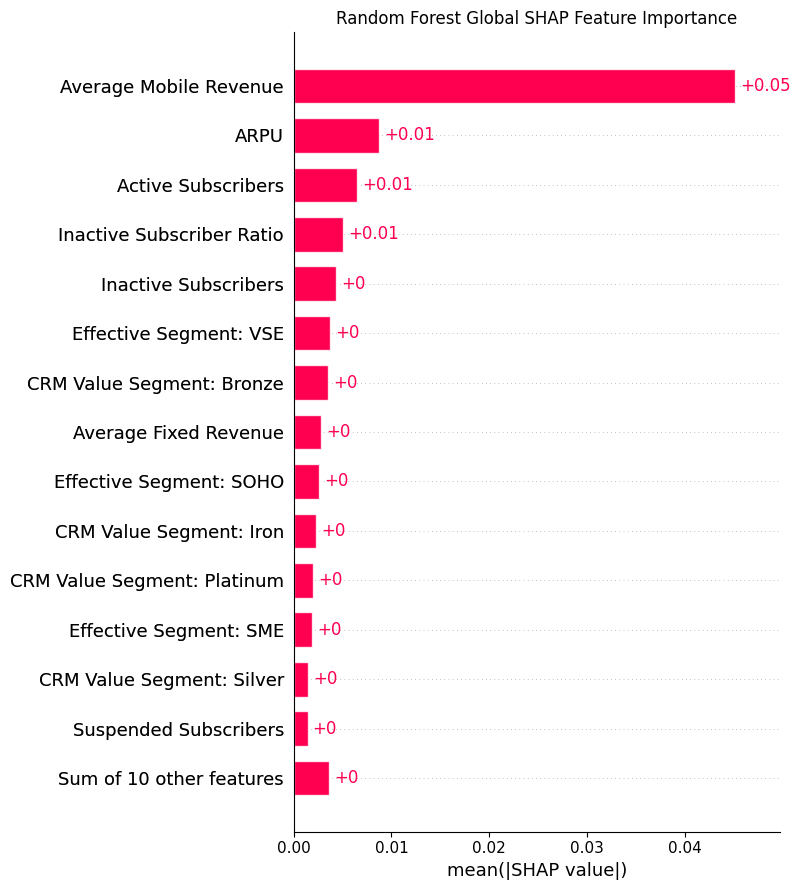

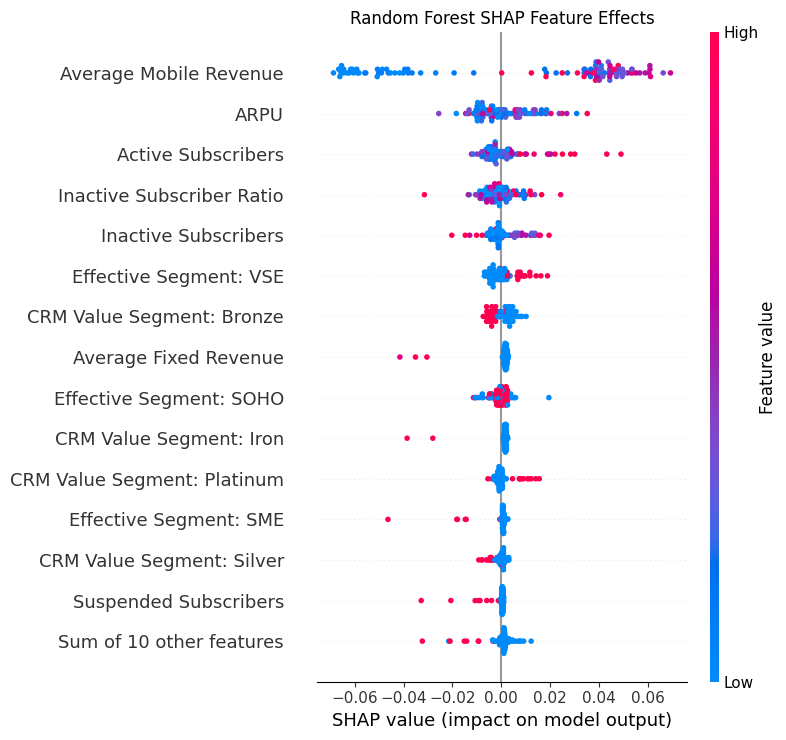


=== Random Forest SHAP Figure Verification ===

Global bar plot : /content/drive/MyDrive/7005SCN_Dissertation/outputs/random_forest_shap_global_bar.png
Beeswarm plot   : /content/drive/MyDrive/7005SCN_Dissertation/outputs/random_forest_shap_beeswarm.png

RF_SHAP_VISUALISATIONS_VALID: True


In [ ]:
# ============================================================
# Cell 14 — Random Forest Global SHAP Visualisations
# ============================================================

import os
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Output paths
# ------------------------------------------------------------

RF_SHAP_BAR_PATH = os.path.join(
    OUTPUTS,
    "random_forest_shap_global_bar.png"
)

RF_SHAP_BEESWARM_PATH = os.path.join(
    OUTPUTS,
    "random_forest_shap_beeswarm.png"
)


# ------------------------------------------------------------
# Global SHAP bar plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

shap.plots.bar(
    rf_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "Random Forest Global SHAP Feature Importance"
)

plt.tight_layout()

plt.savefig(
    RF_SHAP_BAR_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# SHAP beeswarm plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

shap.plots.beeswarm(
    rf_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "Random Forest SHAP Feature Effects"
)

plt.tight_layout()

plt.savefig(
    RF_SHAP_BEESWARM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Verify figures
# ------------------------------------------------------------

assert os.path.exists(
    RF_SHAP_BAR_PATH
)

assert os.path.exists(
    RF_SHAP_BEESWARM_PATH
)

assert os.path.getsize(
    RF_SHAP_BAR_PATH
) > 0

assert os.path.getsize(
    RF_SHAP_BEESWARM_PATH
) > 0


print(
    "\n=== Random Forest SHAP Figure Verification ===\n"
)

print(
    "Global bar plot :",
    RF_SHAP_BAR_PATH
)

print(
    "Beeswarm plot   :",
    RF_SHAP_BEESWARM_PATH
)

print(
    "\nRF_SHAP_VISUALISATIONS_VALID: True"
)

### Random Forest SHAP Interpretation

Average Mobile Revenue was the most influential feature in the stratified held-out explanation sample, with a mean absolute SHAP value of 0.0451. ARPU, Active Subscribers, Inactive Subscriber Ratio and Inactive Subscribers followed in that order.

The beeswarm plot showed that higher Average Mobile Revenue and Active Subscribers values generally contributed positively to predicted churn probability, while lower Average Mobile Revenue values tended to contribute negatively. Other features showed smaller or more variable effects.

The top-five ranking matched LightGBM, suggesting similar influential predictors across the two ensembles. However, Random Forest used model-agnostic SHAP on a stratified 100-observation subset, explaining churn probabilities, whereas LightGBM used native TreeSHAP on the full test set and explained raw model outputs. Their absolute SHAP values are therefore not directly comparable.

## 3.5 XGBoost SHAP Explainability

SHAP is applied to the frozen imbalance-aware XGBoost model using its persisted native gradient-boosted tree representation. The native booster is extracted directly from the loaded Spark XGBoost model, allowing TreeSHAP to calculate feature attributions efficiently without reconstructing or retraining the model.

Global explainability is evaluated across the complete held-out test set using mean absolute SHAP values and SHAP feature-effect visualisations. This provides both an overall ranking of influential predictors and information about the direction and distribution of their contributions across individual observations.

As with the preceding analyses, the validated 24-feature ordering and human-readable display labels are retained. No model fitting, hyperparameter optimisation or modification is performed.

In [ ]:
# ============================================================
# Cell 15 — XGBoost Native TreeSHAP Analysis
# ============================================================

import os
import numpy as np
import pandas as pd
import shap


print("=== XGBoost SHAP Analysis ===\n")


# ------------------------------------------------------------
# Retrieve native booster from the frozen Spark XGBoost model
# ------------------------------------------------------------

xgb_booster = xgb_frozen_model.get_booster()

print(
    "Native booster feature count:",
    xgb_booster.num_features()
)

assert xgb_booster.num_features() == 24


# ------------------------------------------------------------
# Initialise native TreeExplainer
# ------------------------------------------------------------

xgb_explainer = shap.TreeExplainer(
    xgb_booster
)


# ------------------------------------------------------------
# Calculate SHAP values across complete held-out test set
# ------------------------------------------------------------

xgb_shap_values = xgb_explainer(
    X_test_tree_explain
)


# ------------------------------------------------------------
# Validate SHAP output
# ------------------------------------------------------------

print(
    "SHAP values shape :",
    xgb_shap_values.values.shape
)

print(
    "Test matrix shape :",
    X_test_tree_explain.shape
)


assert xgb_shap_values.values.shape == (
    1691,
    24
)

assert np.isfinite(
    xgb_shap_values.values
).all()

assert np.isfinite(
    np.asarray(
        xgb_shap_values.base_values
    )
).all()


# ------------------------------------------------------------
# Global mean absolute SHAP importance
# ------------------------------------------------------------

xgb_mean_abs_shap = np.mean(
    np.abs(
        xgb_shap_values.values
    ),
    axis=0
)


xgb_shap_importance_df = pd.DataFrame({
    "Feature":
        feature_names_display,

    "Mean Absolute SHAP":
        xgb_mean_abs_shap
})


xgb_shap_importance_df = (
    xgb_shap_importance_df
    .sort_values(
        "Mean Absolute SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n=== XGBoost Global SHAP Importance ===\n"
)

display(
    xgb_shap_importance_df.round(6)
)


# ------------------------------------------------------------
# SHAP output information
# ------------------------------------------------------------

xgb_base_values = np.asarray(
    xgb_shap_values.base_values
).reshape(-1)


print(
    "\nBase value sample :",
    float(
        xgb_base_values[0]
    )
)

print(
    "Maximum |SHAP|    :",
    float(
        np.abs(
            xgb_shap_values.values
        ).max()
    )
)


# ------------------------------------------------------------
# Persist numerical SHAP artefacts
# ------------------------------------------------------------

XGB_SHAP_ARRAY_PATH = os.path.join(
    OUTPUTS,
    "xgboost_shap_values.npz"
)

XGB_SHAP_IMPORTANCE_PATH = os.path.join(
    OUTPUTS,
    "xgboost_shap_importance.csv"
)


np.savez_compressed(
    XGB_SHAP_ARRAY_PATH,

    shap_values=
        xgb_shap_values.values,

    base_values=
        xgb_base_values,

    data=
        X_test_tree_explain.to_numpy(),

    labels=
        y_test
)


xgb_shap_importance_df.to_csv(
    XGB_SHAP_IMPORTANCE_PATH,
    index=False
)


# ------------------------------------------------------------
# Artefact verification
# ------------------------------------------------------------

assert os.path.exists(
    XGB_SHAP_ARRAY_PATH
)

assert os.path.getsize(
    XGB_SHAP_ARRAY_PATH
) > 0

assert os.path.exists(
    XGB_SHAP_IMPORTANCE_PATH
)

assert os.path.getsize(
    XGB_SHAP_IMPORTANCE_PATH
) > 0


print(
    "\nSaved SHAP arrays :",
    XGB_SHAP_ARRAY_PATH
)

print(
    "Saved importance  :",
    XGB_SHAP_IMPORTANCE_PATH
)

print(
    "\nXGBOOST_SHAP_VALID: True"
)

=== XGBoost SHAP Analysis ===

Native booster feature count: 24
SHAP values shape : (1691, 24)
Test matrix shape : (1691, 24)

=== XGBoost Global SHAP Importance ===



,Feature,Mean Absolute SHAP
0,Average Mobile Revenue,0.235797
1,ARPU,0.079354
2,Active Subscribers,0.077018
3,Inactive Subscriber Ratio,0.046274
4,Inactive Subscribers,0.020746
5,CRM Value Segment: Iron,0.019488
6,Average Fixed Revenue,0.014675
7,CRM Value Segment: Bronze,0.012468
8,CRM Value Segment: SE,0.010141
9,CRM Value Segment: Silver,0.005556



Base value sample : 0.00039600179297849536
Maximum |SHAP|    : 1.5538909435272217

Saved SHAP arrays : /content/drive/MyDrive/7005SCN_Dissertation/outputs/xgboost_shap_values.npz
Saved importance  : /content/drive/MyDrive/7005SCN_Dissertation/outputs/xgboost_shap_importance.csv

XGBOOST_SHAP_VALID: True


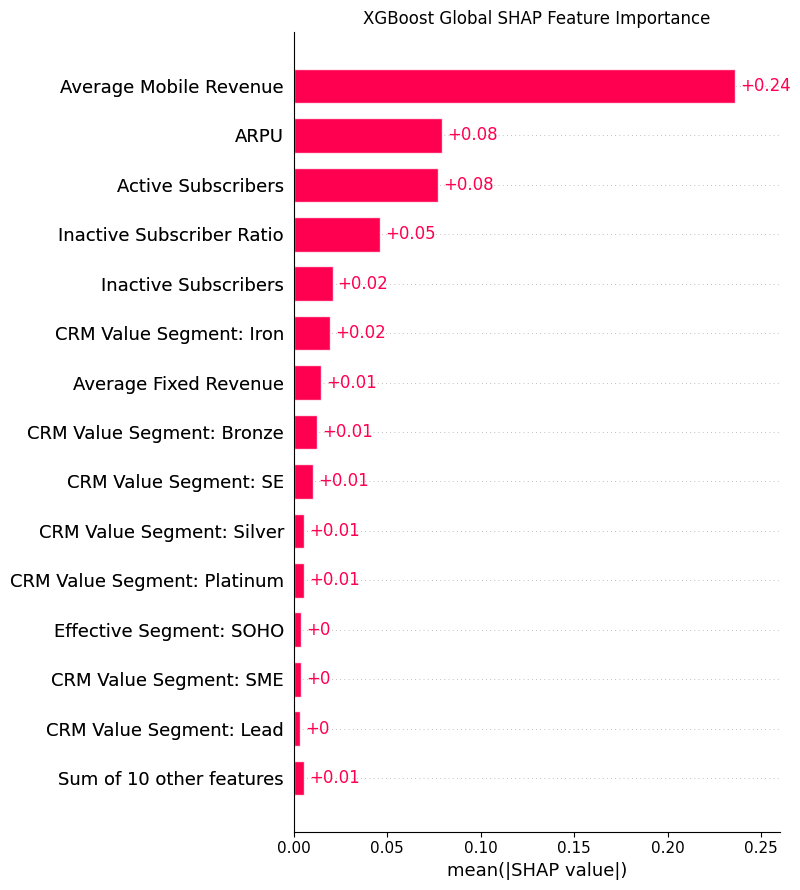

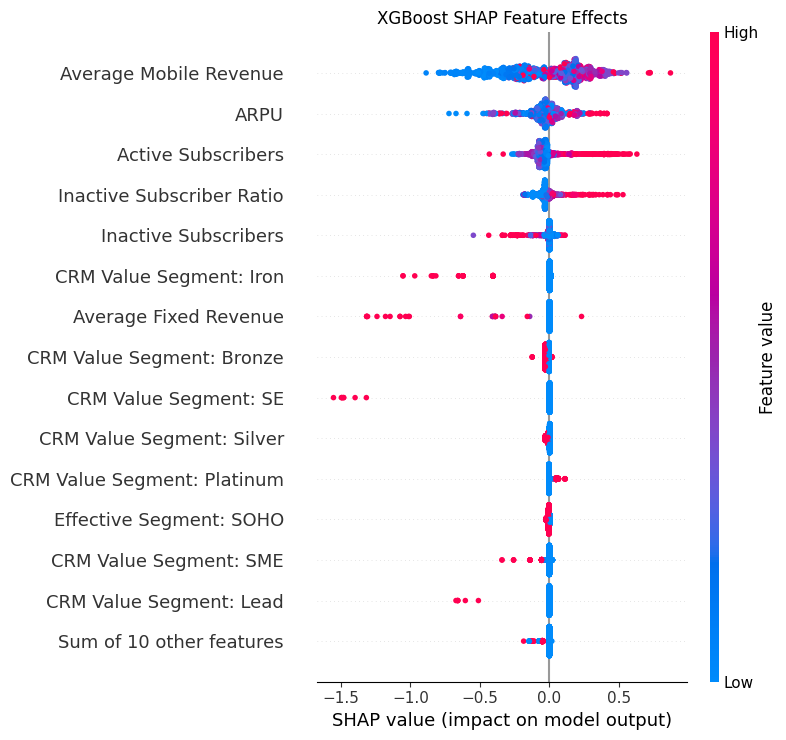


=== XGBoost SHAP Figure Verification ===

Global bar plot : /content/drive/MyDrive/7005SCN_Dissertation/outputs/xgboost_shap_global_bar.png
Beeswarm plot   : /content/drive/MyDrive/7005SCN_Dissertation/outputs/xgboost_shap_beeswarm.png

XGBOOST_SHAP_VISUALISATIONS_VALID: True


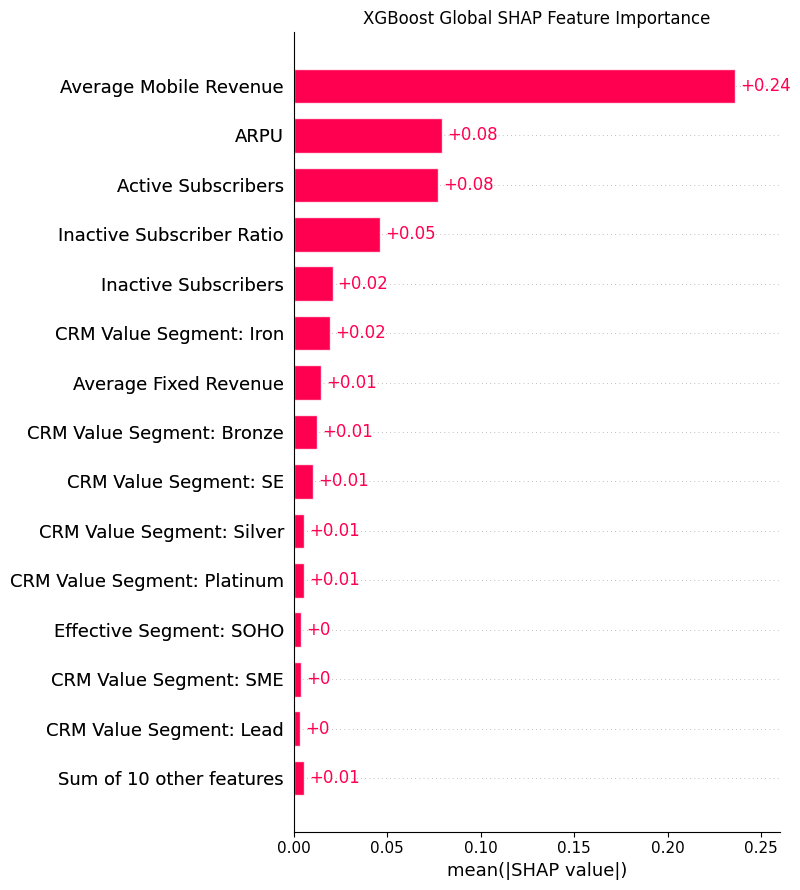

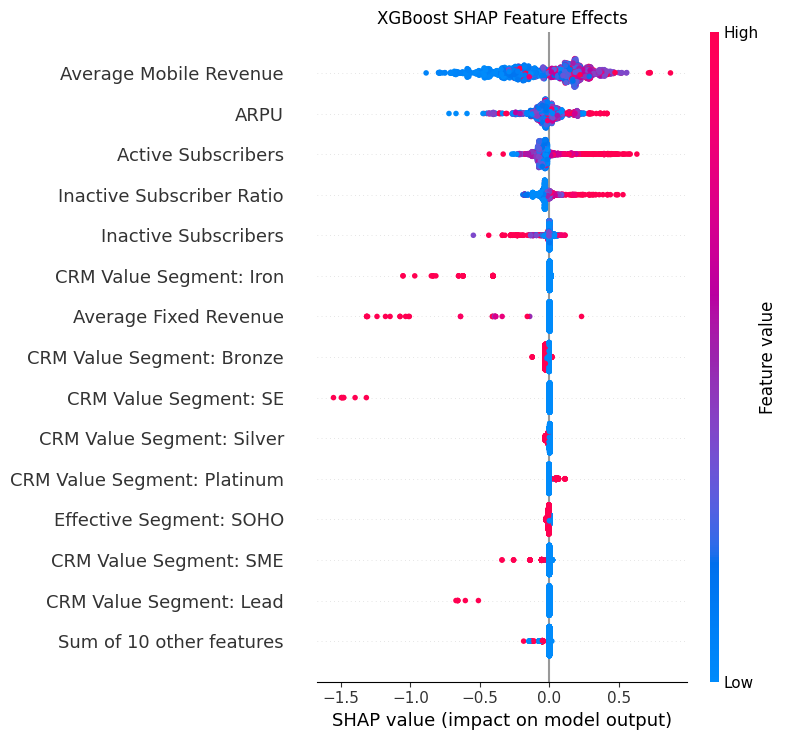


=== XGBoost SHAP Figure Verification ===

Global bar plot : /content/drive/MyDrive/7005SCN_Dissertation/outputs/xgboost_shap_global_bar.png
Beeswarm plot   : /content/drive/MyDrive/7005SCN_Dissertation/outputs/xgboost_shap_beeswarm.png

XGBOOST_SHAP_VISUALISATIONS_VALID: True


In [ ]:
# ============================================================
# Cell 16 — XGBoost Global SHAP Visualisations
# ============================================================

import os
import matplotlib.pyplot as plt


# Output paths
XGB_SHAP_BAR_PATH = os.path.join(
    OUTPUTS,
    "xgboost_shap_global_bar.png"
)

XGB_SHAP_BEESWARM_PATH = os.path.join(
    OUTPUTS,
    "xgboost_shap_beeswarm.png"
)


# Global SHAP bar plot
plt.figure(figsize=(10, 8))

shap.plots.bar(
    xgb_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "XGBoost Global SHAP Feature Importance"
)

plt.tight_layout()

plt.savefig(
    XGB_SHAP_BAR_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# SHAP beeswarm plot
plt.figure(figsize=(10, 8))

shap.plots.beeswarm(
    xgb_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "XGBoost SHAP Feature Effects"
)

plt.tight_layout()

plt.savefig(
    XGB_SHAP_BEESWARM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Verification
assert os.path.exists(XGB_SHAP_BAR_PATH)
assert os.path.exists(XGB_SHAP_BEESWARM_PATH)

assert os.path.getsize(XGB_SHAP_BAR_PATH) > 0
assert os.path.getsize(XGB_SHAP_BEESWARM_PATH) > 0


print("\n=== XGBoost SHAP Figure Verification ===\n")

print(
    "Global bar plot :",
    XGB_SHAP_BAR_PATH
)

print(
    "Beeswarm plot   :",
    XGB_SHAP_BEESWARM_PATH
)

print(
    "\nXGBOOST_SHAP_VISUALISATIONS_VALID: True"
)# ============================================================
# Cell 16 — XGBoost Global SHAP Visualisations
# ============================================================

import os
import matplotlib.pyplot as plt


# Output paths
XGB_SHAP_BAR_PATH = os.path.join(
    OUTPUTS,
    "xgboost_shap_global_bar.png"
)

XGB_SHAP_BEESWARM_PATH = os.path.join(
    OUTPUTS,
    "xgboost_shap_beeswarm.png"
)


# Global SHAP bar plot
plt.figure(figsize=(10, 8))

shap.plots.bar(
    xgb_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "XGBoost Global SHAP Feature Importance"
)

plt.tight_layout()

plt.savefig(
    XGB_SHAP_BAR_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# SHAP beeswarm plot
plt.figure(figsize=(10, 8))

shap.plots.beeswarm(
    xgb_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "XGBoost SHAP Feature Effects"
)

plt.tight_layout()

plt.savefig(
    XGB_SHAP_BEESWARM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Verification
assert os.path.exists(XGB_SHAP_BAR_PATH)
assert os.path.exists(XGB_SHAP_BEESWARM_PATH)

assert os.path.getsize(XGB_SHAP_BAR_PATH) > 0
assert os.path.getsize(XGB_SHAP_BEESWARM_PATH) > 0


print("\n=== XGBoost SHAP Figure Verification ===\n")

print(
    "Global bar plot :",
    XGB_SHAP_BAR_PATH
)

print(
    "Beeswarm plot   :",
    XGB_SHAP_BEESWARM_PATH
)

print(
    "\nXGBOOST_SHAP_VISUALISATIONS_VALID: True"
)

### XGBoost SHAP Interpretation

Average Mobile Revenue was the highest-ranked feature across the held-out test set, with a mean absolute SHAP value of approximately 0.236. The next four features were ARPU, Active Subscribers, Inactive Subscriber Ratio and Inactive Subscribers.

The beeswarm plot showed variable, non-linear feature effects. Higher Active Subscribers and Inactive Subscriber Ratio values frequently contributed positively to the model output, while Average Mobile Revenue contributed in both directions. CRM Value Segment: Iron also showed notable negative contributions for some observations.

The top-five ranking matched both Random Forest and LightGBM, reinforcing the consistency of influential predictors across the ensemble models. Absolute SHAP magnitudes were not compared across models because their explanation methods, output scales and sampling designs differed. Cross-model agreement is examined more systematically in Section 4.

## 3.6 Decision Tree Intrinsic Interpretability and SHAP Explainability

The frozen Decision Tree provides greater intrinsic interpretability than the ensemble tree models because its predictions are generated through an explicit hierarchy of feature-based decision rules. The fitted tree structure can therefore be inspected directly without requiring a post-hoc explanation method.

The tree structure and split-based feature importance are first examined to identify the predictors used by the fitted model. These intrinsic measures are treated separately from SHAP and are not described as SHAP feature importance.

To maintain comparability with the other non-linear models, SHAP-based attribution is subsequently considered for the frozen Decision Tree. This enables its predictive behaviour to be examined within the same general explainability framework while retaining the distinction between intrinsic tree rules and post-hoc feature attribution.

In [ ]:
# ============================================================
# Cell 17 — Decision Tree Intrinsic Interpretability
# ============================================================

import os
import numpy as np
import pandas as pd


print("=== Decision Tree Intrinsic Interpretability ===\n")


# ------------------------------------------------------------
# Basic frozen-tree structure
# ------------------------------------------------------------

print(
    "Tree depth        :",
    dt_frozen_model.depth
)

print(
    "Number of nodes   :",
    dt_frozen_model.numNodes
)

print(
    "Number of features:",
    dt_frozen_model.numFeatures
)


assert dt_frozen_model.numFeatures == 24


# ------------------------------------------------------------
# Built-in split-based feature importance
#
# IMPORTANT:
# This is intrinsic Decision Tree feature importance,
# NOT SHAP.
# ------------------------------------------------------------

dt_feature_importance = np.asarray(
    dt_frozen_model.featureImportances.toArray()
)


assert len(dt_feature_importance) == 24

assert np.isfinite(
    dt_feature_importance
).all()


dt_importance_df = pd.DataFrame({
    "Feature":
        feature_names_display,

    "Tree Feature Importance":
        dt_feature_importance
})


dt_importance_df = (
    dt_importance_df
    .sort_values(
        "Tree Feature Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n=== Decision Tree Split-Based Feature Importance ===\n"
)

display(
    dt_importance_df.round(6)
)


# ------------------------------------------------------------
# Count features actually used by the fitted tree
# ------------------------------------------------------------

dt_used_features = dt_importance_df[
    dt_importance_df[
        "Tree Feature Importance"
    ] > 0
]


print(
    "\nFeatures with non-zero tree importance:",
    len(dt_used_features)
)


# ------------------------------------------------------------
# Preview the actual fitted decision rules
#
# The complete debug string is preserved separately because
# a depth-10 tree may be too large for useful notebook display.
# ------------------------------------------------------------

dt_debug_string = (
    dt_frozen_model.toDebugString
)

dt_debug_lines = (
    dt_debug_string.splitlines()
)


print(
    "Decision-rule lines:",
    len(dt_debug_lines)
)

print(
    "\n=== Decision Tree Rule Preview ===\n"
)

for line in dt_debug_lines[:40]:
    print(line)

if len(dt_debug_lines) > 40:
    print(
        "\n... output truncated in notebook; "
        "complete tree saved to file."
    )


# ------------------------------------------------------------
# Persist intrinsic interpretability artefacts
# ------------------------------------------------------------

DT_IMPORTANCE_PATH = os.path.join(
    OUTPUTS,
    "decision_tree_intrinsic_feature_importance.csv"
)

DT_RULES_PATH = os.path.join(
    OUTPUTS,
    "decision_tree_complete_rules.txt"
)


dt_importance_df.to_csv(
    DT_IMPORTANCE_PATH,
    index=False
)


with open(
    DT_RULES_PATH,
    "w",
    encoding="utf-8"
) as f:
    f.write(dt_debug_string)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert os.path.exists(
    DT_IMPORTANCE_PATH
)

assert os.path.exists(
    DT_RULES_PATH
)

assert os.path.getsize(
    DT_IMPORTANCE_PATH
) > 0

assert os.path.getsize(
    DT_RULES_PATH
) > 0


print(
    "\n=== Decision Tree Artefact Verification ===\n"
)

print(
    "Importance table :",
    DT_IMPORTANCE_PATH
)

print(
    "Complete rules   :",
    DT_RULES_PATH
)

print(
    "\nDT_INTRINSIC_INTERPRETABILITY_VALID: True"
)

=== Decision Tree Intrinsic Interpretability ===

Tree depth        : 10
Number of nodes   : 405
Number of features: 24

=== Decision Tree Split-Based Feature Importance ===



,Feature,Tree Feature Importance
0,Average Mobile Revenue,0.244712
1,ARPU,0.244274
2,Active Subscribers,0.154520
3,Inactive Subscribers,0.130464
4,Inactive Subscriber Ratio,0.121774
5,CRM Value Segment: Bronze,0.025986
6,CRM Value Segment: Gold,0.021428
7,Effective Segment: VSE,0.012812
8,CRM Value Segment: Iron,0.010919
9,Effective Segment: SOHO,0.008495



Features with non-zero tree importance: 15
Decision-rule lines: 608

=== Decision Tree Rule Preview ===

DecisionTreeClassificationModel: uid=DecisionTreeClassifier_07f5a6e79b43, depth=10, numNodes=405, numClasses=2, numFeatures=24
  If (feature 20 <= 99.58500000000001)
   If (feature 22 <= 27.715)
    If (feature 20 <= 72.75)
     If (feature 18 <= 4.5)
      If (feature 18 <= 2.5)
       If (feature 22 <= 14.205)
        If (feature 23 <= 0.18019480519480519)
         If (feature 22 <= 8.82)
          Predict: 0.0
         Else (feature 22 > 8.82)
          If (feature 20 <= 52.415)
           If (feature 20 <= 48.75)
            Predict: 0.0
           Else (feature 20 > 48.75)
            Predict: 1.0
          Else (feature 20 > 52.415)
           Predict: 0.0
        Else (feature 23 > 0.18019480519480519)
         If (feature 20 <= 57.585)
          If (feature 22 <= 13.004999999999999)
           If (feature 22 <= 8.82)
            Predict: 1.0
           Else (feature 22 > 8.

### Decision Tree Intrinsic Interpretation

The frozen imbalance-aware Decision Tree has a maximum depth of 10 and contains 405 nodes, producing 608 lines of explicit decision rules. Although the model is intrinsically interpretable because its predictions can be traced through observable feature-based splits, the size of the fitted tree limits the practicality of interpreting the complete model manually. Its interpretability is therefore greater than that of the ensemble models in structural terms, but substantially lower than would be expected from a small or shallow decision tree.

The intrinsic split-based feature importance identifies Average Mobile Revenue and ARPU as the two most influential predictors, followed by Active Subscribers, Inactive Subscribers and Inactive Subscriber Ratio. Fifteen of the 24 encoded inputs are used by the fitted tree with non-zero importance.

Inspection of the upper decision rules provides additional evidence of this structure. The initial branches primarily involve Average Mobile Revenue, ARPU, Inactive Subscribers and Inactive Subscriber Ratio, indicating that these predictors contribute directly to major divisions within the fitted decision tree.

This broadly agrees with the explainability results obtained from the ensemble models. Random Forest, XGBoost and LightGBM identified the same group of five revenue and subscriber characteristics as their leading SHAP predictors, although the exact ordering differs slightly for the Decision Tree. The consistency across distinct model structures suggests that these variables form a recurring core of the predictive relationships learned from the available telecommunications data.

The Decision Tree feature-importance values reported here are intrinsic split-based importance measures and are not SHAP values. They describe how the fitted tree uses predictors when constructing its decision structure and should not be interpreted as causal effects.

### Decision Tree Model-Agnostic SHAP Analysis

To complement the intrinsic decision-rule analysis and provide a common attribution framework with the other evaluated models, model-agnostic permutation SHAP is applied to the frozen PySpark Decision Tree.

The same held-out explanation observations and training reference distribution used for the Random Forest analysis are retained. This provides a consistent sampling basis for the two PySpark tree models while avoiding model reconstruction or retraining. The SHAP analysis explains the churn probabilities produced directly by the persisted Decision Tree.

In [ ]:
# ============================================================
# Cell 18 — Decision Tree Model-Agnostic SHAP Analysis
# ============================================================

import time
import numpy as np
import pandas as pd
import shap

from pyspark.ml.linalg import Vectors
from pyspark.sql import Row


print("=== Decision Tree Model-Agnostic SHAP Analysis ===\n")


# ------------------------------------------------------------
# Prediction wrapper around exact frozen Spark Decision Tree
# ------------------------------------------------------------

def dt_predict_churn_probability(X):

    X = np.asarray(
        X,
        dtype=float
    )

    spark_rows = [
        Row(
            features_unscaled=Vectors.dense(
                row.tolist()
            )
        )
        for row in X
    ]

    prediction_df = (
        spark.createDataFrame(
            spark_rows
        )
    )

    predictions = (
        dt_frozen_model
        .transform(prediction_df)
        .select("probability")
        .collect()
    )

    return np.array([
        float(
            row["probability"][1]
        )
        for row in predictions
    ])


# ------------------------------------------------------------
# Validate wrapper
# ------------------------------------------------------------

dt_wrapper_test = (
    dt_predict_churn_probability(
        X_rf_explain.iloc[:5].to_numpy()
    )
)

assert len(dt_wrapper_test) == 5
assert np.isfinite(dt_wrapper_test).all()

assert np.all(
    (dt_wrapper_test >= 0.0)
    &
    (dt_wrapper_test <= 1.0)
)


print(
    "First five churn probabilities:"
)

print(
    np.round(
        dt_wrapper_test,
        6
    )
)


# ------------------------------------------------------------
# Use SAME background as Random Forest
# ------------------------------------------------------------

dt_masker = shap.maskers.Independent(
    X_rf_background,
    max_samples=50
)


dt_shap_explainer = shap.Explainer(
    dt_predict_churn_probability,
    dt_masker,
    algorithm="permutation",
    feature_names=feature_names_display,
    seed=42
)


# ------------------------------------------------------------
# Explain SAME 100 held-out observations used for RF
# ------------------------------------------------------------

DT_MIN_EVALS = (
    2 * X_rf_explain.shape[1]
    + 1
)

start_time = time.time()

dt_shap_values = dt_shap_explainer(
    X_rf_explain,
    max_evals=DT_MIN_EVALS
)

dt_shap_runtime = (
    time.time()
    - start_time
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert dt_shap_values.values.shape == (
    100,
    24
)

assert np.isfinite(
    dt_shap_values.values
).all()

assert np.isfinite(
    np.asarray(
        dt_shap_values.base_values
    )
).all()


# ------------------------------------------------------------
# Additivity validation
# ------------------------------------------------------------

dt_explain_probabilities = (
    dt_predict_churn_probability(
        X_rf_explain.to_numpy()
    )
)

dt_reconstructed = (
    np.asarray(
        dt_shap_values.base_values
    ).reshape(-1)
    +
    dt_shap_values.values.sum(
        axis=1
    )
)

dt_max_reconstruction_error = float(
    np.max(
        np.abs(
            dt_explain_probabilities
            - dt_reconstructed
        )
    )
)


assert dt_max_reconstruction_error < 1e-5


print(
    "\nSHAP values shape :",
    dt_shap_values.values.shape
)

print(
    "Runtime seconds   :",
    round(dt_shap_runtime, 2)
)

print(
    "Maximum reconstruction error:",
    dt_max_reconstruction_error
)


# ------------------------------------------------------------
# Global SHAP importance
# ------------------------------------------------------------

dt_mean_abs_shap = np.mean(
    np.abs(
        dt_shap_values.values
    ),
    axis=0
)


dt_shap_importance_df = pd.DataFrame({
    "Feature":
        feature_names_display,

    "Mean Absolute SHAP":
        dt_mean_abs_shap
})


dt_shap_importance_df = (
    dt_shap_importance_df
    .sort_values(
        "Mean Absolute SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n=== Decision Tree SHAP Importance ===\n"
)

display(
    dt_shap_importance_df.round(6)
)


print(
    "\nDT_SHAP_VALID: True"
)

=== Decision Tree Model-Agnostic SHAP Analysis ===

First five churn probabilities:
[0.       0.665176 0.63816  0.       0.63816 ]


PermutationExplainer explainer: 101it [01:00,  1.54it/s]


SHAP values shape : (100, 24)
Runtime seconds   : 60.23
Maximum reconstruction error: 5.551115123125783e-16

=== Decision Tree SHAP Importance ===



,Feature,Mean Absolute SHAP
0,Average Mobile Revenue,0.136658
1,Active Subscribers,0.067182
2,ARPU,0.064135
3,Inactive Subscribers,0.042291
4,Inactive Subscriber Ratio,0.039745
5,CRM Value Segment: Bronze,0.036029
6,Effective Segment: VSE,0.019856
7,CRM Value Segment: Iron,0.006820
8,CRM Value Segment: Platinum,0.006218
9,CRM Value Segment: SME,0.004507



DT_SHAP_VALID: True


### Decision Tree SHAP Interpretation

The model-agnostic SHAP analysis confirms that **Average Mobile Revenue** is the most influential predictor in the frozen Decision Tree for the stratified held-out explanation sample. Active Subscribers, ARPU, Inactive Subscribers and Inactive Subscriber Ratio constitute the remaining four leading predictors.

The SHAP ranking differs slightly from the intrinsic split-based feature-importance ranking. In particular, the intrinsic measure ranked ARPU marginally above Active Subscribers, whereas SHAP ranked Active Subscribers above ARPU. This difference is expected because the two approaches quantify different aspects of model behaviour: split-based importance reflects the contribution of features to the fitted tree's splitting structure, while SHAP measures their contributions to predictions across the evaluated observations.

Despite these ordering differences, both approaches identify the same core group of revenue and subscriber characteristics as dominant within the Decision Tree. This group is also consistent with the leading predictors identified by Random Forest, XGBoost and LightGBM, providing further evidence of recurring predictive structure across the evaluated non-linear models.

The Decision Tree SHAP values were calculated using the same 100 held-out observations, 50-observation training reference sample and model-agnostic permutation procedure used for the Random Forest. The resulting values explain predicted churn probability directly and reconstruct the frozen model outputs to numerical precision.

The SHAP results describe the predictive behaviour of the fitted Decision Tree and should not be interpreted as causal effects.

# 4. Cross-Model Explainability Comparison

The explainability results are now compared across the evaluated model families to identify similarities and differences in the predictive relationships learned from the telecommunications data.

Direct comparison of absolute SHAP magnitudes across all models would be inappropriate because the explainability procedures differ in both output scale and sampling design. LightGBM and XGBoost were analysed using native TreeSHAP across the complete held-out test set, whereas Random Forest and Decision Tree required model-agnostic permutation SHAP using a fixed stratified subset. Logistic Regression is intrinsically interpreted through regularised coefficients rather than tree-based SHAP values.

The cross-model analysis therefore focuses primarily on relative feature rankings and agreement in influential predictors, rather than treating SHAP magnitudes as directly comparable quantities. Rank-based comparison provides a common basis for examining whether independently fitted models rely on similar customer characteristics when generating churn predictions.

## 4.1 Cross-Model Feature-Rank Agreement

Feature rankings are derived from the global explainability results for Decision Tree, Random Forest, XGBoost and LightGBM. For each model, features are ranked according to mean absolute SHAP contribution, with rank 1 representing the most influential predictor.

Spearman rank correlation is subsequently used to quantify agreement between the complete feature rankings. Because several models assign exactly zero importance to some features, tied ranks are retained rather than imposing an arbitrary ordering among features with identical attribution values.

The comparison is supplemented by examination of overlap among the highest-ranked predictors, providing an interpretable assessment of whether the models converge on a common predictive feature structure.

In [ ]:
# ============================================================
# Cell 19 — Cross-Model SHAP Feature-Rank Agreement
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr


print("=== Cross-Model Explainability Comparison ===\n")


# ------------------------------------------------------------
# Construct common feature-importance table
#
# Raw magnitudes are retained only to derive within-model
# rankings. They are NOT interpreted as directly comparable
# between models.
# ------------------------------------------------------------

cross_model_importance = pd.DataFrame({
    "Feature": feature_names_display,

    "Decision Tree":
        dt_mean_abs_shap,

    "Random Forest":
        rf_mean_abs_shap,

    "XGBoost":
        xgb_mean_abs_shap,

    "LightGBM":
        lgbm_mean_abs_shap
})


# ------------------------------------------------------------
# Generate within-model ranks
#
# method="average" preserves tied ranks for zero-valued
# features rather than imposing arbitrary ordering.
# ------------------------------------------------------------

model_columns = [
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "LightGBM"
]


rank_table = pd.DataFrame({
    "Feature":
        cross_model_importance["Feature"]
})


for model in model_columns:

    rank_table[
        f"{model} Rank"
    ] = (
        cross_model_importance[model]
        .rank(
            ascending=False,
            method="average"
        )
    )


# ------------------------------------------------------------
# Mean rank across the four non-linear models
#
# This is a descriptive consensus ranking of feature
# importance, NOT a model-performance or interpretability score.
# ------------------------------------------------------------

rank_columns = [
    f"{model} Rank"
    for model in model_columns
]


rank_table[
    "Mean Rank"
] = (
    rank_table[
        rank_columns
    ]
    .mean(axis=1)
)


rank_table = (
    rank_table
    .sort_values(
        "Mean Rank",
        ascending=True
    )
    .reset_index(drop=True)
)


print(
    "=== Cross-Model Feature Ranking ===\n"
)

display(
    rank_table.round(2)
)


# ------------------------------------------------------------
# Spearman rank correlations
# ------------------------------------------------------------

rank_matrix = (
    rank_table
    .set_index("Feature")[
        rank_columns
    ]
)


spearman_matrix = (
    rank_matrix
    .corr(
        method="spearman"
    )
)


# Cleaner labels
spearman_matrix.index = model_columns
spearman_matrix.columns = model_columns


print(
    "\n=== Spearman Rank Correlation ===\n"
)

display(
    spearman_matrix.round(3)
)


# ------------------------------------------------------------
# Top-five feature overlap
# ------------------------------------------------------------

top_five_sets = {}

for model in model_columns:

    model_top_five = (
        cross_model_importance[
            ["Feature", model]
        ]
        .sort_values(
            model,
            ascending=False
        )
        .head(5)["Feature"]
        .tolist()
    )

    top_five_sets[model] = set(
        model_top_five
    )


common_top_five = set.intersection(
    *top_five_sets.values()
)


print(
    "\n=== Top-Five Feature Agreement ===\n"
)

for model in model_columns:

    ordered_top_five = (
        cross_model_importance[
            ["Feature", model]
        ]
        .sort_values(
            model,
            ascending=False
        )
        .head(5)["Feature"]
        .tolist()
    )

    print(
        f"{model}:"
    )

    for rank, feature in enumerate(
        ordered_top_five,
        start=1
    ):
        print(
            f"  {rank}. {feature}"
        )

    print()


print(
    "Features appearing in the top five "
    "of ALL four models:"
)

for feature in sorted(
    common_top_five
):
    print(
        " -",
        feature
    )


print(
    "\nNumber of universally shared top-five features:",
    len(common_top_five)
)


# ------------------------------------------------------------
# Save comparison artefacts
# ------------------------------------------------------------

CROSS_MODEL_RANK_PATH = os.path.join(
    OUTPUTS,
    "cross_model_explainability_ranks.csv"
)

SPEARMAN_PATH = os.path.join(
    OUTPUTS,
    "cross_model_spearman_rank_correlation.csv"
)


rank_table.to_csv(
    CROSS_MODEL_RANK_PATH,
    index=False
)

spearman_matrix.to_csv(
    SPEARMAN_PATH
)


assert os.path.exists(
    CROSS_MODEL_RANK_PATH
)

assert os.path.exists(
    SPEARMAN_PATH
)

assert os.path.getsize(
    CROSS_MODEL_RANK_PATH
) > 0

assert os.path.getsize(
    SPEARMAN_PATH
) > 0


print(
    "\n=== Artefact Verification ===\n"
)

print(
    "Rank table :",
    CROSS_MODEL_RANK_PATH
)

print(
    "Correlation:",
    SPEARMAN_PATH
)

print(
    "\nCROSS_MODEL_RANK_ANALYSIS_VALID: True"
)

=== Cross-Model Explainability Comparison ===

=== Cross-Model Feature Ranking ===



,Feature,Decision Tree Rank,Random Forest Rank,XGBoost Rank,LightGBM Rank,Mean Rank
0,Average Mobile Revenue,1.0,1.0,1.0,1.0,1.00
1,ARPU,3.0,2.0,2.0,2.0,2.25
2,Active Subscribers,2.0,3.0,3.0,3.0,2.75
3,Inactive Subscriber Ratio,5.0,4.0,4.0,4.0,4.25
4,Inactive Subscribers,4.0,5.0,5.0,5.0,4.75
5,CRM Value Segment: Bronze,6.0,7.0,8.0,9.0,7.50
6,CRM Value Segment: Iron,8.0,10.0,6.0,8.0,8.00
7,Average Fixed Revenue,15.0,8.0,7.0,6.0,9.00
8,CRM Value Segment: Platinum,9.0,11.0,11.0,11.0,10.50
9,Effective Segment: VSE,7.0,6.0,17.0,14.0,11.00



=== Spearman Rank Correlation ===



,Decision Tree,Random Forest,XGBoost,LightGBM
Decision Tree,1.000,0.899,0.805,0.806
Random Forest,0.899,1.000,0.813,0.901
XGBoost,0.805,0.813,1.000,0.877
LightGBM,0.806,0.901,0.877,1.000



=== Top-Five Feature Agreement ===

Decision Tree:
  1. Average Mobile Revenue
  2. Active Subscribers
  3. ARPU
  4. Inactive Subscribers
  5. Inactive Subscriber Ratio

Random Forest:
  1. Average Mobile Revenue
  2. ARPU
  3. Active Subscribers
  4. Inactive Subscriber Ratio
  5. Inactive Subscribers

XGBoost:
  1. Average Mobile Revenue
  2. ARPU
  3. Active Subscribers
  4. Inactive Subscriber Ratio
  5. Inactive Subscribers

LightGBM:
  1. Average Mobile Revenue
  2. ARPU
  3. Active Subscribers
  4. Inactive Subscriber Ratio
  5. Inactive Subscribers

Features appearing in the top five of ALL four models:
 - ARPU
 - Active Subscribers
 - Average Mobile Revenue
 - Inactive Subscriber Ratio
 - Inactive Subscribers

Number of universally shared top-five features: 5

=== Artefact Verification ===

Rank table : /content/drive/MyDrive/7005SCN_Dissertation/outputs/cross_model_explainability_ranks.csv
Correlation: /content/drive/MyDrive/7005SCN_Dissertation/outputs/cross_model_spearman

### Cross-Model Feature-Rank Interpretation

The cross-model analysis demonstrates substantial agreement in the predictive feature structures learned by the four non-linear models. All four models identify the same five predictors within their five highest-ranked features: **Average Mobile Revenue, ARPU, Active Subscribers, Inactive Subscriber Ratio and Inactive Subscribers**.

Average Mobile Revenue is ranked as the most influential feature by every model. Random Forest, XGBoost and LightGBM additionally produce exactly the same ordering of the five leading predictors, while Decision Tree retains the same feature group but ranks Active Subscribers above ARPU and Inactive Subscribers above Inactive Subscriber Ratio.

Agreement extends beyond the leading predictors. Pairwise Spearman rank correlations calculated across the complete 24-feature rankings range from approximately 0.805 to 0.901, indicating strong positive correspondence between the models' global feature-importance structures. The strongest agreement is observed between Random Forest and LightGBM (ρ = 0.901), followed closely by Decision Tree and Random Forest (ρ = 0.899). Even the lowest observed correlations remain above 0.80.

These findings provide evidence of cross-model consistency despite substantial differences in model architecture and explainability procedure. The recurring importance of revenue and subscriber characteristics is therefore not attributable to the behaviour of a single algorithm. Instead, independently fitted tree-based models repeatedly identify the same core group of predictors as influential for churn prediction.

The comparison concerns predictive feature attribution rather than causal importance. Furthermore, rank-based comparison is used deliberately because absolute SHAP magnitudes are not directly comparable across all models due to differences in SHAP output scale and explanation sampling.

## 4.2 Explainability Comparison Across Model Families

The Logistic Regression findings are incorporated into the cross-model analysis separately because its intrinsic coefficient-based interpretation is not directly equivalent to SHAP feature attribution. This comparison considers the type of explanation available for each model, the complexity of the fitted predictive structure and the principal features identified by the explainability analysis.

The purpose is not to assign an arbitrary numerical interpretability score, but to identify the practical differences between intrinsic transparency and post-hoc explainability across the evaluated model families.

In [ ]:
# ============================================================
# Cell 20 — Cross-Model Explainability Summary
# ============================================================

import os
import pandas as pd


print("=== Cross-Model Explainability Summary ===\n")


# ------------------------------------------------------------
# Construct qualitative explainability comparison
#
# These categories describe the fitted models and explanation
# methods used in this notebook. They are NOT numerical
# interpretability scores.
# ------------------------------------------------------------

explainability_summary_df = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],

    "Primary Explanation Method": [
        "Intrinsic coefficients",
        "Intrinsic rules + permutation SHAP",
        "Permutation SHAP",
        "Native TreeSHAP",
        "Native TreeSHAP"
    ],

    "Intrinsic / Post-hoc": [
        "Intrinsic",
        "Intrinsic + post-hoc",
        "Post-hoc",
        "Post-hoc",
        "Post-hoc"
    ],

    "Observed Model Complexity": [
        "1 non-zero coefficient from 24 inputs",
        "Depth 10; 405 nodes",
        "50-tree ensemble",
        "50-tree boosted ensemble",
        "50-tree boosted ensemble"
    ],

    "Most Influential Feature": [
        "Average Mobile Revenue",
        "Average Mobile Revenue",
        "Average Mobile Revenue",
        "Average Mobile Revenue",
        "Average Mobile Revenue"
    ],

    "Explainability Scope Demonstrated": [
        "Global intrinsic",
        "Global intrinsic + global SHAP",
        "Global SHAP",
        "Global SHAP",
        "Global + local SHAP"
    ]
})


display(
    explainability_summary_df
)


# ------------------------------------------------------------
# Verify unanimous leading feature
# ------------------------------------------------------------

assert (
    explainability_summary_df[
        "Most Influential Feature"
    ]
    == "Average Mobile Revenue"
).all()


print(
    "\nAll five models identify "
    "Average Mobile Revenue as their "
    "leading retained/influential feature."
)


# ------------------------------------------------------------
# Save artefact
# ------------------------------------------------------------

EXPLAINABILITY_SUMMARY_PATH = os.path.join(
    OUTPUTS,
    "cross_model_explainability_summary.csv"
)


explainability_summary_df.to_csv(
    EXPLAINABILITY_SUMMARY_PATH,
    index=False
)


assert os.path.exists(
    EXPLAINABILITY_SUMMARY_PATH
)

assert os.path.getsize(
    EXPLAINABILITY_SUMMARY_PATH
) > 0


print(
    "\nSaved summary:"
)

print(
    EXPLAINABILITY_SUMMARY_PATH
)

print(
    "\nCROSS_MODEL_EXPLAINABILITY_SUMMARY_VALID: True"
)

=== Cross-Model Explainability Summary ===



,Model,Primary Explanation Method,Intrinsic / Post-hoc,Observed Model Complexity,Most Influential Feature,Explainability Scope Demonstrated
0,Logistic Regression,Intrinsic coefficients,Intrinsic,1 non-zero coefficient from 24 inputs,Average Mobile Revenue,Global intrinsic
1,Decision Tree,Intrinsic rules + permutation SHAP,Intrinsic + post-hoc,Depth 10; 405 nodes,Average Mobile Revenue,Global intrinsic + global SHAP
2,Random Forest,Permutation SHAP,Post-hoc,50-tree ensemble,Average Mobile Revenue,Global SHAP
3,XGBoost,Native TreeSHAP,Post-hoc,50-tree boosted ensemble,Average Mobile Revenue,Global SHAP
4,LightGBM,Native TreeSHAP,Post-hoc,50-tree boosted ensemble,Average Mobile Revenue,Global + local SHAP



All five models identify Average Mobile Revenue as their leading retained/influential feature.

Saved summary:
/content/drive/MyDrive/7005SCN_Dissertation/outputs/cross_model_explainability_summary.csv

CROSS_MODEL_EXPLAINABILITY_SUMMARY_VALID: True


# 5. Stability and Perturbation Analysis

The preceding SHAP analysis identifies which predictors contribute most strongly to the fitted models. A complementary perturbation analysis is conducted to examine whether model predictions remain dependent on these influential features when their observed relationship with churn is deliberately disrupted.

Unlike model retraining or hyperparameter tuning, this analysis leaves each frozen model unchanged. Instead, selected feature values within the held-out test data are perturbed before predictions are regenerated. Any resulting change therefore reflects the sensitivity of the existing fitted model to the modified input information.

The analysis focuses on the five numerical predictors that appeared consistently among the most influential features across the non-linear models: **Average Mobile Revenue, ARPU, Active Subscribers, Inactive Subscriber Ratio and Inactive Subscribers**. Restricting perturbation to these numerical variables also avoids generating invalid combinations among one-hot encoded categorical indicators.

## 5.1 Model-Specific Perturbation Analysis

In [ ]:
# ============================================================
# Cell 21 — Perturbation Analysis Setup
# ============================================================

import numpy as np
import pandas as pd


print("=== Perturbation Analysis Setup ===\n")


# ------------------------------------------------------------
# Features selected from cross-model explainability findings
# ------------------------------------------------------------

PERTURBATION_FEATURES = [
    "Average Mobile Revenue",
    "ARPU",
    "Active Subscribers",
    "Inactive Subscriber Ratio",
    "Inactive Subscribers"
]


# ------------------------------------------------------------
# Recover exact positions in the validated 24-feature vectors
# ------------------------------------------------------------

feature_position_map = {
    feature: index
    for index, feature
    in enumerate(feature_names_display)
}


perturbation_positions = {
    feature:
        feature_position_map[feature]

    for feature
    in PERTURBATION_FEATURES
}


print("Selected perturbation features:\n")

for feature, position in perturbation_positions.items():
    print(
        f"{position:>2} -> {feature}"
    )


# Authoritative positions from the validated feature mapping
expected_positions = {
    "Average Mobile Revenue": 20,
    "ARPU": 22,
    "Active Subscribers": 17,
    "Inactive Subscriber Ratio": 23,
    "Inactive Subscribers": 18
}


assert perturbation_positions == expected_positions


# ------------------------------------------------------------
# Held-out sample size
#
# y_test was prepared in Cell 7 and corresponds to the
# complete untouched held-out test set.
# ------------------------------------------------------------

N_TEST = len(y_test)

assert N_TEST == 1691


# ------------------------------------------------------------
# Create deterministic permutation indices
#
# A separate reproducible permutation is created for each
# feature. These exact indices will later be applied to each
# model's corresponding test representation.
# ------------------------------------------------------------

PERTURBATION_SEED = 42

perturbation_indices = {}


for i, feature in enumerate(
    PERTURBATION_FEATURES
):

    rng = np.random.default_rng(
        PERTURBATION_SEED + i
    )

    perturbation_indices[feature] = (
        rng.permutation(N_TEST)
    )


# ------------------------------------------------------------
# Validate permutation indices
# ------------------------------------------------------------

expected_indices = np.arange(N_TEST)


for feature, indices in perturbation_indices.items():

    assert len(indices) == N_TEST

    assert np.array_equal(
        np.sort(indices),
        expected_indices
    )


print(
    "\nHeld-out observations:",
    N_TEST
)

print(
    "Perturbation seed:",
    PERTURBATION_SEED
)

print(
    "Number of selected features:",
    len(PERTURBATION_FEATURES)
)


# ------------------------------------------------------------
# Verify that each index sequence genuinely rearranges rows
# ------------------------------------------------------------

verification_rows = []


for feature in PERTURBATION_FEATURES:

    indices = perturbation_indices[
        feature
    ]

    proportion_rows_reassigned = np.mean(
        indices != expected_indices
    )

    verification_rows.append({
        "Feature":
            feature,

        "Valid Complete Permutation":
            np.array_equal(
                np.sort(indices),
                expected_indices
            ),

        "Proportion of Rows Reassigned":
            proportion_rows_reassigned
    })


perturbation_verification_df = pd.DataFrame(
    verification_rows
)


print(
    "\n=== Perturbation Index Verification ===\n"
)

display(
    perturbation_verification_df.round(4)
)


assert (
    perturbation_verification_df[
        "Valid Complete Permutation"
    ]
).all()


assert (
    perturbation_verification_df[
        "Proportion of Rows Reassigned"
    ] > 0
).all()


print(
    "\nPERTURBATION_SETUP_VALID: True"
)

=== Perturbation Analysis Setup ===

Selected perturbation features:

20 -> Average Mobile Revenue
22 -> ARPU
17 -> Active Subscribers
23 -> Inactive Subscriber Ratio
18 -> Inactive Subscribers

Held-out observations: 1691
Perturbation seed: 42
Number of selected features: 5

=== Perturbation Index Verification ===



,Feature,Valid Complete Permutation,Proportion of Rows Reassigned
0,Average Mobile Revenue,True,0.9988
1,ARPU,True,0.9994
2,Active Subscribers,True,0.9994
3,Inactive Subscriber Ratio,True,1.0000
4,Inactive Subscribers,True,1.0000



PERTURBATION_SETUP_VALID: True


In [ ]:
# ============================================================
# Cell 22 — Identify Full Held-Out Feature Matrices
# ============================================================

import numpy as np
import pandas as pd


print("=== Full Held-Out Matrix Discovery ===\n")


matrix_candidates = []


# ------------------------------------------------------------
# Take a fixed snapshot of globals before iterating
# ------------------------------------------------------------

global_snapshot = list(
    globals().items()
)


for name, obj in global_snapshot:

    # pandas DataFrame
    if isinstance(obj, pd.DataFrame):

        if obj.shape == (1691, 24):

            matrix_candidates.append({
                "Variable": name,
                "Type": "pandas.DataFrame",
                "Shape": str(obj.shape)
            })

    # NumPy array
    elif isinstance(obj, np.ndarray):

        if (
            obj.ndim == 2
            and obj.shape == (1691, 24)
        ):

            matrix_candidates.append({
                "Variable": name,
                "Type": "numpy.ndarray",
                "Shape": str(obj.shape)
            })


matrix_candidates_df = pd.DataFrame(
    matrix_candidates
)


print(
    "Objects matching the expected "
    "held-out feature shape (1691, 24):\n"
)


if len(matrix_candidates_df) > 0:

    display(
        matrix_candidates_df
    )

else:

    print(
        "No in-memory 1691 x 24 matrix found."
    )


# ------------------------------------------------------------
# Additional known explainability objects
# ------------------------------------------------------------

print("\n=== Known Existing Objects ===\n")


for name in [
    "X_rf_explain",
    "X_rf_background",
    "y_test"
]:

    if name in globals():

        obj = globals()[name]

        shape = getattr(
            obj,
            "shape",
            None
        )

        if shape is None:

            try:
                shape = (len(obj),)
            except Exception:
                shape = "Unknown"

        print(
            f"{name}: {shape}"
        )


print(
    "\nMATRIX_DISCOVERY_COMPLETE: True"
)

=== Full Held-Out Matrix Discovery ===

Objects matching the expected held-out feature shape (1691, 24):



,Variable,Type,Shape
0,X_test_tree_np,numpy.ndarray,"(1691, 24)"
1,X_test_lr_np,numpy.ndarray,"(1691, 24)"
2,X_test_tree_explain,pandas.DataFrame,"(1691, 24)"
3,X_test_lr_explain,pandas.DataFrame,"(1691, 24)"



=== Known Existing Objects ===

X_rf_explain: (100, 24)
X_rf_background: (50, 24)
y_test: (1691,)

MATRIX_DISCOVERY_COMPLETE: True


In [ ]:
# ============================================================
# Cell 23 — Construct and Validate Perturbed Test Inputs
#          (LightGBM / Unscaled Representation)
# ============================================================

import numpy as np
import pandas as pd


print("=== Construct Perturbed Held-Out Inputs ===\n")


# ------------------------------------------------------------
# Authoritative unscaled held-out matrix
# ------------------------------------------------------------

X_test_unscaled = np.asarray(
    X_test_tree_np,
    dtype=float
)


assert X_test_unscaled.shape == (
    1691,
    24
)


# ------------------------------------------------------------
# Construct one perturbed matrix per selected feature
# ------------------------------------------------------------

perturbed_test_matrices = {}

perturbation_value_checks = []


for feature in PERTURBATION_FEATURES:

    position = perturbation_positions[
        feature
    ]

    permutation = perturbation_indices[
        feature
    ]

    # Copy entire held-out matrix
    X_perturbed = (
        X_test_unscaled.copy()
    )

    original_values = (
        X_test_unscaled[
            :,
            position
        ].copy()
    )

    # --------------------------------------------------------
    # ACTUAL perturbation:
    # replace the feature inside the 24-dimensional input
    # vector with its permuted held-out values
    # --------------------------------------------------------

    X_perturbed[
        :,
        position
    ] = (
        original_values[
            permutation
        ]
    )

    perturbed_values = (
        X_perturbed[
            :,
            position
        ]
    )

    # --------------------------------------------------------
    # Verification
    # --------------------------------------------------------

    marginal_preserved = (
        np.array_equal(
            np.sort(original_values),
            np.sort(perturbed_values)
        )
    )

    proportion_changed = float(
        np.mean(
            original_values
            != perturbed_values
        )
    )

    # All non-target columns must remain exactly unchanged
    unchanged_columns = [
        i
        for i in range(
            X_test_unscaled.shape[1]
        )
        if i != position
    ]

    other_features_unchanged = (
        np.array_equal(
            X_test_unscaled[
                :,
                unchanged_columns
            ],
            X_perturbed[
                :,
                unchanged_columns
            ]
        )
    )

    assert marginal_preserved
    assert proportion_changed > 0
    assert other_features_unchanged

    perturbed_test_matrices[
        feature
    ] = X_perturbed

    perturbation_value_checks.append({
        "Feature":
            feature,

        "Position":
            position,

        "Marginal Values Preserved":
            marginal_preserved,

        "Proportion Values Changed":
            proportion_changed,

        "Other 23 Features Unchanged":
            other_features_unchanged
    })


# ------------------------------------------------------------
# Display verification table
# ------------------------------------------------------------

perturbation_value_checks_df = (
    pd.DataFrame(
        perturbation_value_checks
    )
)


display(
    perturbation_value_checks_df.round(4)
)


# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

assert len(
    perturbed_test_matrices
) == 5


for feature, matrix in (
    perturbed_test_matrices.items()
):

    assert matrix.shape == (
        1691,
        24
    )

    assert np.isfinite(
        matrix
    ).all()


print(
    "\nNumber of perturbed matrices:",
    len(perturbed_test_matrices)
)

print(
    "Each matrix shape:",
    (1691, 24)
)

print(
    "\nPERTURBED_INPUTS_VALID: True"
)

=== Construct Perturbed Held-Out Inputs ===



,Feature,Position,Marginal Values Preserved,Proportion Values Changed,Other 23 Features Unchanged
0,Average Mobile Revenue,20,True,0.9982,True
1,ARPU,22,True,0.9988,True
2,Active Subscribers,17,True,0.9243,True
3,Inactive Subscriber Ratio,23,True,0.7735,True
4,Inactive Subscribers,18,True,0.7173,True



Number of perturbed matrices: 5
Each matrix shape: (1691, 24)

PERTURBED_INPUTS_VALID: True


In [ ]:
# ============================================================
# Cell 24 — LightGBM Perturbation Sensitivity
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    precision_recall_curve,
    auc
)


print("=== LightGBM Perturbation Sensitivity ===\n")


# ------------------------------------------------------------
# Helper: PR-AUC using same precision-recall integration
# convention used during LightGBM evaluation
# ------------------------------------------------------------

def calculate_pr_auc(
    y_true,
    probabilities
):

    precision, recall, _ = (
        precision_recall_curve(
            y_true,
            probabilities
        )
    )

    return auc(
        recall,
        precision
    )


# ------------------------------------------------------------
# Original frozen LightGBM predictions
# ------------------------------------------------------------

lgbm_original_prob = (
    lgbm_frozen_model.predict_proba(
        X_test_unscaled
    )[:, 1]
)


assert len(
    lgbm_original_prob
) == 1691

assert np.isfinite(
    lgbm_original_prob
).all()


lgbm_original_roc_auc = (
    roc_auc_score(
        y_test,
        lgbm_original_prob
    )
)

lgbm_original_pr_auc = (
    calculate_pr_auc(
        y_test,
        lgbm_original_prob
    )
)


print(
    "Original ROC-AUC:",
    round(
        lgbm_original_roc_auc,
        6
    )
)

print(
    "Original PR-AUC :",
    round(
        lgbm_original_pr_auc,
        6
    )
)


# ------------------------------------------------------------
# Evaluate each perturbed feature
# ------------------------------------------------------------

lgbm_perturbation_rows = []


for feature in PERTURBATION_FEATURES:

    X_perturbed = (
        perturbed_test_matrices[
            feature
        ]
    )

    perturbed_prob = (
        lgbm_frozen_model.predict_proba(
            X_perturbed
        )[:, 1]
    )


    # ----------------------------------------
    # Prediction-level sensitivity
    # ----------------------------------------

    mean_abs_probability_change = float(
        np.mean(
            np.abs(
                perturbed_prob
                - lgbm_original_prob
            )
        )
    )


    # ----------------------------------------
    # Ranking/discrimination metrics
    # ----------------------------------------

    perturbed_roc_auc = (
        roc_auc_score(
            y_test,
            perturbed_prob
        )
    )

    perturbed_pr_auc = (
        calculate_pr_auc(
            y_test,
            perturbed_prob
        )
    )


    roc_auc_change = (
        perturbed_roc_auc
        - lgbm_original_roc_auc
    )

    pr_auc_change = (
        perturbed_pr_auc
        - lgbm_original_pr_auc
    )


    lgbm_perturbation_rows.append({

        "Feature":
            feature,

        "Mean Absolute Probability Change":
            mean_abs_probability_change,

        "Perturbed ROC-AUC":
            perturbed_roc_auc,

        "ROC-AUC Change":
            roc_auc_change,

        "Perturbed PR-AUC":
            perturbed_pr_auc,

        "PR-AUC Change":
            pr_auc_change
    })


# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

lgbm_perturbation_df = (
    pd.DataFrame(
        lgbm_perturbation_rows
    )
    .sort_values(
        "Mean Absolute Probability Change",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n=== LightGBM Perturbation Results ===\n"
)

display(
    lgbm_perturbation_df.round(6)
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert len(
    lgbm_perturbation_df
) == 5

assert np.isfinite(
    lgbm_perturbation_df.select_dtypes(
        include=[np.number]
    ).to_numpy()
).all()


print(
    "\nMost prediction-sensitive feature:"
)

print(
    lgbm_perturbation_df.loc[
        0,
        "Feature"
    ]
)


print(
    "\nLIGHTGBM_PERTURBATION_VALID: True"
)

=== LightGBM Perturbation Sensitivity ===

Original ROC-AUC: 0.576209
Original PR-AUC : 0.083449

=== LightGBM Perturbation Results ===



,Feature,Mean Absolute Probability Change,Perturbed ROC-AUC,ROC-AUC Change,Perturbed PR-AUC,PR-AUC Change
0,Average Mobile Revenue,0.092403,0.483874,-0.092335,0.064430,-0.019019
1,ARPU,0.049312,0.559634,-0.016575,0.086972,0.003522
2,Active Subscribers,0.030497,0.551653,-0.024556,0.075726,-0.007724
3,Inactive Subscriber Ratio,0.018868,0.560221,-0.015988,0.080430,-0.003019
4,Inactive Subscribers,0.010975,0.566118,-0.010091,0.077957,-0.005493



Most prediction-sensitive feature:
Average Mobile Revenue

LIGHTGBM_PERTURBATION_VALID: True


### LightGBM Perturbation Interpretation

The perturbation analysis provides additional evidence that the frozen LightGBM model is particularly dependent on **Average Mobile Revenue**. Permuting this feature produced the largest mean absolute change in predicted churn probability (0.0924) and reduced ROC-AUC from 0.5762 to 0.4839. PR-AUC also declined from 0.0834 to 0.0644, representing the largest deterioration among the five examined predictors.

ARPU produced the second-largest change in individual predicted probabilities (0.0493) and reduced ROC-AUC by approximately 0.0166. However, its perturbed PR-AUC increased slightly. This illustrates that perturbation effects can differ between evaluation measures, particularly in an imbalanced classification problem, and therefore no single metric is treated as a complete measure of model sensitivity.

Perturbing Active Subscribers, Inactive Subscriber Ratio and Inactive Subscribers also altered predictions and generally reduced both ROC-AUC and PR-AUC, although their effects were smaller than that observed for Average Mobile Revenue.

These results broadly reinforce the LightGBM SHAP analysis, in which Average Mobile Revenue was also the highest-ranked global predictor. The agreement between feature attribution and perturbation sensitivity provides complementary evidence that the fitted model relies strongly on this feature. However, the experiment measures predictive dependence rather than causality, and small changes in individual performance metrics should be interpreted cautiously given the modest discrimination achieved by the model.

In [ ]:
# ============================================================
# Cell 25 — Construct and Validate LR Perturbed Inputs
# ============================================================

import numpy as np
import pandas as pd


print("=== Logistic Regression Perturbation Inputs ===\n")


# ------------------------------------------------------------
# Authoritative scaled held-out representation
# ------------------------------------------------------------

X_test_scaled = np.asarray(
    X_test_lr_np,
    dtype=float
)


assert X_test_scaled.shape == (
    1691,
    24
)


# ------------------------------------------------------------
# Apply SAME row permutations used for unscaled models
# ------------------------------------------------------------

lr_perturbed_test_matrices = {}

lr_perturbation_checks = []


for feature in PERTURBATION_FEATURES:

    position = perturbation_positions[
        feature
    ]

    permutation = perturbation_indices[
        feature
    ]


    X_perturbed = (
        X_test_scaled.copy()
    )


    original_values = (
        X_test_scaled[
            :,
            position
        ].copy()
    )


    X_perturbed[
        :,
        position
    ] = (
        original_values[
            permutation
        ]
    )


    perturbed_values = (
        X_perturbed[
            :,
            position
        ]
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    marginal_preserved = (
        np.array_equal(
            np.sort(original_values),
            np.sort(perturbed_values)
        )
    )


    proportion_changed = float(
        np.mean(
            original_values
            != perturbed_values
        )
    )


    unchanged_columns = [
        i
        for i in range(
            X_test_scaled.shape[1]
        )
        if i != position
    ]


    other_features_unchanged = (
        np.array_equal(
            X_test_scaled[
                :,
                unchanged_columns
            ],
            X_perturbed[
                :,
                unchanged_columns
            ]
        )
    )


    assert marginal_preserved
    assert other_features_unchanged


    lr_perturbed_test_matrices[
        feature
    ] = X_perturbed


    lr_perturbation_checks.append({

        "Feature":
            feature,

        "Position":
            position,

        "Marginal Values Preserved":
            marginal_preserved,

        "Proportion Values Changed":
            proportion_changed,

        "Other 23 Features Unchanged":
            other_features_unchanged
    })


# ------------------------------------------------------------
# Display verification
# ------------------------------------------------------------

lr_perturbation_checks_df = (
    pd.DataFrame(
        lr_perturbation_checks
    )
)


display(
    lr_perturbation_checks_df.round(4)
)


# ------------------------------------------------------------
# Cross-representation verification
#
# The SAME row permutation must have been used for each
# corresponding feature in both scaled and unscaled inputs.
# ------------------------------------------------------------

for feature in PERTURBATION_FEATURES:

    indices = perturbation_indices[
        feature
    ]

    assert np.array_equal(
        np.sort(indices),
        np.arange(1691)
    )


assert len(
    lr_perturbed_test_matrices
) == 5


print(
    "\nScaled LR matrices:",
    len(
        lr_perturbed_test_matrices
    )
)

print(
    "Each matrix shape:",
    (1691, 24)
)

print(
    "\nLR_PERTURBED_INPUTS_VALID: True"
)

=== Logistic Regression Perturbation Inputs ===



,Feature,Position,Marginal Values Preserved,Proportion Values Changed,Other 23 Features Unchanged
0,Average Mobile Revenue,20,True,0.9982,True
1,ARPU,22,True,0.9988,True
2,Active Subscribers,17,True,0.9243,True
3,Inactive Subscriber Ratio,23,True,0.7735,True
4,Inactive Subscribers,18,True,0.7173,True



Scaled LR matrices: 5
Each matrix shape: (1691, 24)

LR_PERTURBED_INPUTS_VALID: True


In [ ]:
# ============================================================
# Cell 26 — Logistic Regression Perturbation Sensitivity
# ============================================================

import numpy as np
import pandas as pd

from pyspark.ml.linalg import Vectors
from pyspark.sql import Row
from sklearn.metrics import roc_auc_score


print("=== Logistic Regression Perturbation Sensitivity ===\n")


# ------------------------------------------------------------
# Confirm the feature column expected by the frozen LR model
# ------------------------------------------------------------

LR_FEATURES_COL = (
    lr_frozen_model.getFeaturesCol()
)

print(
    "Frozen LR features column:",
    LR_FEATURES_COL
)

assert LR_FEATURES_COL == "features_scaled"


# ------------------------------------------------------------
# Prediction wrapper around exact frozen Spark LR model
# ------------------------------------------------------------

def lr_predict_churn_probability(X):

    X = np.asarray(
        X,
        dtype=float
    )

    spark_rows = [
        Row(
            features_scaled=Vectors.dense(
                row.tolist()
            )
        )
        for row in X
    ]

    prediction_df = spark.createDataFrame(
        spark_rows
    )

    predictions = (
        lr_frozen_model
        .transform(prediction_df)
        .select("probability")
        .collect()
    )

    return np.array([
        float(
            row["probability"][1]
        )
        for row in predictions
    ])


# ------------------------------------------------------------
# Original frozen LR probabilities
# ------------------------------------------------------------

lr_original_prob = (
    lr_predict_churn_probability(
        X_test_scaled
    )
)


assert len(
    lr_original_prob
) == 1691

assert np.isfinite(
    lr_original_prob
).all()


lr_original_roc_auc = (
    roc_auc_score(
        y_test,
        lr_original_prob
    )
)

lr_original_pr_auc = (
    calculate_pr_auc(
        y_test,
        lr_original_prob
    )
)


print(
    "Original ROC-AUC:",
    round(
        lr_original_roc_auc,
        6
    )
)

print(
    "Original PR-AUC :",
    round(
        lr_original_pr_auc,
        6
    )
)


# ------------------------------------------------------------
# Evaluate each perturbation
# ------------------------------------------------------------

lr_perturbation_rows = []


for feature in PERTURBATION_FEATURES:

    X_perturbed = (
        lr_perturbed_test_matrices[
            feature
        ]
    )

    perturbed_prob = (
        lr_predict_churn_probability(
            X_perturbed
        )
    )


    mean_abs_probability_change = float(
        np.mean(
            np.abs(
                perturbed_prob
                - lr_original_prob
            )
        )
    )


    perturbed_roc_auc = (
        roc_auc_score(
            y_test,
            perturbed_prob
        )
    )

    perturbed_pr_auc = (
        calculate_pr_auc(
            y_test,
            perturbed_prob
        )
    )


    lr_perturbation_rows.append({

        "Feature":
            feature,

        "Mean Absolute Probability Change":
            mean_abs_probability_change,

        "Perturbed ROC-AUC":
            perturbed_roc_auc,

        "ROC-AUC Change":
            perturbed_roc_auc
            - lr_original_roc_auc,

        "Perturbed PR-AUC":
            perturbed_pr_auc,

        "PR-AUC Change":
            perturbed_pr_auc
            - lr_original_pr_auc
    })


# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

lr_perturbation_df = (
    pd.DataFrame(
        lr_perturbation_rows
    )
    .sort_values(
        "Mean Absolute Probability Change",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n=== Logistic Regression Perturbation Results ===\n"
)

display(
    lr_perturbation_df.round(10)
)


# ------------------------------------------------------------
# Validate against frozen LR coefficient structure
# ------------------------------------------------------------

non_mobile_features = [
    feature
    for feature in PERTURBATION_FEATURES
    if feature != "Average Mobile Revenue"
]


non_mobile_effects = (
    lr_perturbation_df.loc[
        lr_perturbation_df[
            "Feature"
        ].isin(
            non_mobile_features
        ),
        "Mean Absolute Probability Change"
    ]
    .to_numpy()
)


max_zero_coefficient_effect = float(
    np.max(
        non_mobile_effects
    )
)


mobile_effect = float(
    lr_perturbation_df.loc[
        lr_perturbation_df[
            "Feature"
        ]
        == "Average Mobile Revenue",
        "Mean Absolute Probability Change"
    ].iloc[0]
)


print(
    "\nMaximum probability effect among "
    "the four zero-coefficient features:"
)

print(
    max_zero_coefficient_effect
)


print(
    "\nAverage Mobile Revenue effect:"
)

print(
    mobile_effect
)


# ------------------------------------------------------------
# Expected structural validation
# ------------------------------------------------------------

assert (
    max_zero_coefficient_effect
    < 1e-10
)

assert mobile_effect > 0


print(
    "\nLR_PERTURBATION_VALID: True"
)

=== Logistic Regression Perturbation Sensitivity ===

Frozen LR features column: features_scaled
Original ROC-AUC: 0.588103
Original PR-AUC : 0.081792

=== Logistic Regression Perturbation Results ===



,Feature,Mean Absolute Probability Change,Perturbed ROC-AUC,ROC-AUC Change,Perturbed PR-AUC,PR-AUC Change
0,Average Mobile Revenue,0.011432,0.478411,-0.109692,0.060775,-0.021017
1,ARPU,0.000000,0.588103,0.000000,0.081792,0.000000
2,Active Subscribers,0.000000,0.588103,0.000000,0.081792,0.000000
3,Inactive Subscriber Ratio,0.000000,0.588103,0.000000,0.081792,0.000000
4,Inactive Subscribers,0.000000,0.588103,0.000000,0.081792,0.000000



Maximum probability effect among the four zero-coefficient features:
0.0

Average Mobile Revenue effect:
0.011432349989491773

LR_PERTURBATION_VALID: True


### Logistic Regression Perturbation Interpretation

The Logistic Regression perturbation results closely reproduce the structure observed in the intrinsic coefficient analysis. Permuting **Average Mobile Revenue**, the only predictor with a non-zero coefficient in the frozen regularised model, produced a measurable mean absolute change in predicted churn probability of approximately 0.0114.

Disrupting this feature also reduced ROC-AUC from 0.5881 to 0.4784 and PR-AUC from 0.0818 to 0.0608, indicating that the model's limited discriminatory capability depends almost entirely on Average Mobile Revenue.

In contrast, perturbing ARPU, Active Subscribers, Inactive Subscriber Ratio and Inactive Subscribers produced no change in predicted probabilities or evaluation metrics. This is consistent with the fitted Elastic Net Logistic Regression model assigning exactly zero coefficients to these predictors.

The agreement between coefficient-based interpretation and independent perturbation analysis provides strong internal consistency for the interpretation of the frozen Logistic Regression model. However, this simplicity also highlights the narrowness of the fitted linear representation relative to the richer feature structures identified by the non-linear models.

In [ ]:
# ============================================================
# Cell 27 — DT, RF and XGBoost Perturbation Sensitivity
# ============================================================

import numpy as np
import pandas as pd

from pyspark.ml.linalg import Vectors
from pyspark.sql import Row
from sklearn.metrics import roc_auc_score


print("=== DT / RF / XGBoost Perturbation Sensitivity ===\n")


# ------------------------------------------------------------
# Resolve the feature-vector column expected by a frozen model
# ------------------------------------------------------------

def resolve_spark_features_col(model):

    # Standard Spark ML models
    if hasattr(model, "getFeaturesCol"):
        return model.getFeaturesCol()

    # XGBoost Spark model
    if hasattr(model, "features_col"):
        return model.getOrDefault(
            model.features_col
        )

    raise AttributeError(
        "Could not determine the model's feature column."
    )


# ------------------------------------------------------------
# Generic frozen Spark probability wrapper
# ------------------------------------------------------------

def spark_model_predict_probability(
    model,
    X
):

    X = np.asarray(
        X,
        dtype=float
    )

    features_col = (
        resolve_spark_features_col(
            model
        )
    )

    spark_rows = [
        Row(
            **{
                features_col:
                    Vectors.dense(
                        row.tolist()
                    )
            }
        )
        for row in X
    ]

    prediction_df = (
        spark.createDataFrame(
            spark_rows
        )
    )

    prediction_rows = (
        model
        .transform(
            prediction_df
        )
        .select(
            "probability"
        )
        .collect()
    )

    probabilities = np.array([
        float(
            row["probability"][1]
        )
        for row in prediction_rows
    ])

    return probabilities


# ------------------------------------------------------------
# Frozen models
# ------------------------------------------------------------

spark_perturbation_models = {
    "Decision Tree":
        dt_frozen_model,

    "Random Forest":
        rf_frozen_model,

    "XGBoost":
        xgb_frozen_model
}


# ------------------------------------------------------------
# Confirm expected input columns
# ------------------------------------------------------------

print(
    "Frozen model feature columns:"
)

for model_name, model in spark_perturbation_models.items():

    print(
        f"{model_name}:",
        resolve_spark_features_col(
            model
        )
    )


# ------------------------------------------------------------
# Run perturbation analysis
# ------------------------------------------------------------

spark_perturbation_rows = []

spark_original_probabilities = {}


for model_name, model in spark_perturbation_models.items():

    print(
        f"\n--- {model_name} ---"
    )


    # --------------------------------------------------------
    # Original probabilities
    # --------------------------------------------------------

    original_prob = (
        spark_model_predict_probability(
            model,
            X_test_unscaled
        )
    )

    spark_original_probabilities[
        model_name
    ] = original_prob


    assert len(
        original_prob
    ) == 1691

    assert np.isfinite(
        original_prob
    ).all()


    original_roc_auc = (
        roc_auc_score(
            y_test,
            original_prob
        )
    )

    original_pr_auc = (
        calculate_pr_auc(
            y_test,
            original_prob
        )
    )


    print(
        "Original ROC-AUC:",
        round(
            original_roc_auc,
            6
        )
    )

    print(
        "Original PR-AUC :",
        round(
            original_pr_auc,
            6
        )
    )


    # --------------------------------------------------------
    # Five deterministic feature perturbations
    # --------------------------------------------------------

    for feature in PERTURBATION_FEATURES:

        X_perturbed = (
            perturbed_test_matrices[
                feature
            ]
        )


        perturbed_prob = (
            spark_model_predict_probability(
                model,
                X_perturbed
            )
        )


        mean_abs_probability_change = float(
            np.mean(
                np.abs(
                    perturbed_prob
                    - original_prob
                )
            )
        )


        perturbed_roc_auc = (
            roc_auc_score(
                y_test,
                perturbed_prob
            )
        )

        perturbed_pr_auc = (
            calculate_pr_auc(
                y_test,
                perturbed_prob
            )
        )


        spark_perturbation_rows.append({

            "Model":
                model_name,

            "Feature":
                feature,

            "Mean Absolute Probability Change":
                mean_abs_probability_change,

            "Original ROC-AUC":
                original_roc_auc,

            "Perturbed ROC-AUC":
                perturbed_roc_auc,

            "ROC-AUC Change":
                (
                    perturbed_roc_auc
                    - original_roc_auc
                ),

            "Original PR-AUC":
                original_pr_auc,

            "Perturbed PR-AUC":
                perturbed_pr_auc,

            "PR-AUC Change":
                (
                    perturbed_pr_auc
                    - original_pr_auc
                )
        })


# ------------------------------------------------------------
# Combined result table
# ------------------------------------------------------------

spark_perturbation_df = (
    pd.DataFrame(
        spark_perturbation_rows
    )
    .sort_values(
        [
            "Model",
            "Mean Absolute Probability Change"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n=== Combined DT / RF / XGBoost Results ===\n"
)

display(
    spark_perturbation_df[
        [
            "Model",
            "Feature",
            "Mean Absolute Probability Change",
            "Perturbed ROC-AUC",
            "ROC-AUC Change",
            "Perturbed PR-AUC",
            "PR-AUC Change"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# Most prediction-sensitive feature for each model
# ------------------------------------------------------------

most_sensitive_features = (
    spark_perturbation_df
    .sort_values(
        "Mean Absolute Probability Change",
        ascending=False
    )
    .groupby(
        "Model",
        as_index=False
    )
    .first()
)


print(
    "\n=== Most Prediction-Sensitive Feature per Model ===\n"
)

display(
    most_sensitive_features[
        [
            "Model",
            "Feature",
            "Mean Absolute Probability Change"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert len(
    spark_perturbation_df
) == 15

assert spark_perturbation_df[
    "Model"
].nunique() == 3

assert spark_perturbation_df[
    "Feature"
].nunique() == 5

assert np.isfinite(
    spark_perturbation_df[
        [
            "Mean Absolute Probability Change",
            "Perturbed ROC-AUC",
            "ROC-AUC Change",
            "Perturbed PR-AUC",
            "PR-AUC Change"
        ]
    ].to_numpy()
).all()


print(
    "\nSPARK_MODEL_PERTURBATION_VALID: True"
)

=== DT / RF / XGBoost Perturbation Sensitivity ===

Frozen model feature columns:
Decision Tree: features_unscaled
Random Forest: features_unscaled
XGBoost: features_unscaled

--- Decision Tree ---
Original ROC-AUC: 0.523578
Original PR-AUC : 0.081475

--- Random Forest ---
Original ROC-AUC: 0.591202
Original PR-AUC : 0.101223

--- XGBoost ---
Original ROC-AUC: 0.575838
Original PR-AUC : 0.085447

=== Combined DT / RF / XGBoost Results ===



,Model,Feature,Mean Absolute Probability Change,Perturbed ROC-AUC,ROC-AUC Change,Perturbed PR-AUC,PR-AUC Change
0,Decision Tree,Average Mobile Revenue,0.264109,0.494256,-0.029323,0.063181,-0.018294
1,Decision Tree,Active Subscribers,0.136779,0.553594,0.030016,0.116145,0.034669
2,Decision Tree,ARPU,0.120700,0.517230,-0.006348,0.077924,-0.003552
3,Decision Tree,Inactive Subscriber Ratio,0.083604,0.477120,-0.046458,0.068647,-0.012828
4,Decision Tree,Inactive Subscribers,0.059761,0.519016,-0.004563,0.078375,-0.003100
5,Random Forest,Average Mobile Revenue,0.055874,0.510767,-0.080435,0.080482,-0.020741
6,Random Forest,ARPU,0.016974,0.571779,-0.019424,0.082993,-0.018230
7,Random Forest,Active Subscribers,0.013404,0.581183,-0.010020,0.098609,-0.002614
8,Random Forest,Inactive Subscriber Ratio,0.011823,0.561515,-0.029688,0.085778,-0.015445
9,Random Forest,Inactive Subscribers,0.010159,0.586740,-0.004462,0.097821,-0.003403



=== Most Prediction-Sensitive Feature per Model ===



,Model,Feature,Mean Absolute Probability Change
0,Decision Tree,Average Mobile Revenue,0.264109
1,Random Forest,Average Mobile Revenue,0.055874
2,XGBoost,Average Mobile Revenue,0.082141



SPARK_MODEL_PERTURBATION_VALID: True


### Decision Tree, Random Forest and XGBoost Perturbation Interpretation

Across all three models, **Average Mobile Revenue** produced the largest mean absolute change in predicted churn probability. This provides further evidence that the feature is central to the fitted non-linear models and is consistent with the preceding SHAP and Decision Tree importance analyses.

For the Random Forest, perturbing Average Mobile Revenue changed predicted probabilities by an average of 0.0559 and reduced ROC-AUC by approximately 0.080 and PR-AUC by 0.0207. The remaining four predictors produced smaller probability changes, although ARPU and Inactive Subscriber Ratio also caused noticeable reductions in predictive discrimination.

XGBoost exhibited a similar pattern. Average Mobile Revenue generated the largest probability change (0.0821) and reduced ROC-AUC by approximately 0.0604. ARPU, Active Subscribers, Inactive Subscriber Ratio and Inactive Subscribers produced progressively smaller prediction changes, broadly corresponding to their earlier SHAP importance ordering.

The Decision Tree was considerably more sensitive to feature permutation than the ensemble models in absolute probability terms. Average Mobile Revenue produced a mean absolute probability change of 0.2641, while Active Subscribers produced a change of 0.1368. However, perturbing Active Subscribers increased rather than reduced both ROC-AUC and PR-AUC. This demonstrates that strong predictive dependence on a feature does not necessarily imply that the dependence improves held-out predictive performance. The result is consistent with the comparatively weak and structurally complex fitted Decision Tree, where individual splits may introduce unstable or poorly generalising decision boundaries.

Consequently, perturbation sensitivity is interpreted primarily as evidence of model dependence on a predictor rather than as a direct measure of predictor usefulness. Changes in predictive metrics provide complementary evidence but may be non-monotonic, particularly for a weak model and an imbalanced held-out sample.

In [ ]:
# ============================================================
# Cell 28 — Cross-Model Perturbation Comparison
# ============================================================

import os
import numpy as np
import pandas as pd


print("=== Cross-Model Perturbation Comparison ===\n")


# ------------------------------------------------------------
# Standardise the three result sources
# ------------------------------------------------------------

lr_cross = (
    lr_perturbation_df
    .copy()
)

lr_cross.insert(
    0,
    "Model",
    "Logistic Regression"
)


lgbm_cross = (
    lgbm_perturbation_df
    .copy()
)

lgbm_cross.insert(
    0,
    "Model",
    "LightGBM"
)


spark_cross = (
    spark_perturbation_df[
        [
            "Model",
            "Feature",
            "Mean Absolute Probability Change",
            "Perturbed ROC-AUC",
            "ROC-AUC Change",
            "Perturbed PR-AUC",
            "PR-AUC Change"
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# Combine all five frozen models
# ------------------------------------------------------------

cross_model_perturbation_df = (
    pd.concat(
        [
            lr_cross[
                [
                    "Model",
                    "Feature",
                    "Mean Absolute Probability Change",
                    "Perturbed ROC-AUC",
                    "ROC-AUC Change",
                    "Perturbed PR-AUC",
                    "PR-AUC Change"
                ]
            ],
            spark_cross,
            lgbm_cross[
                [
                    "Model",
                    "Feature",
                    "Mean Absolute Probability Change",
                    "Perturbed ROC-AUC",
                    "ROC-AUC Change",
                    "Perturbed PR-AUC",
                    "PR-AUC Change"
                ]
            ]
        ],
        ignore_index=True
    )
)


# ------------------------------------------------------------
# Add within-model sensitivity rank
#
# Rank 1 = largest mean absolute probability change.
# This is descriptive only; it is NOT a combined model score.
# ------------------------------------------------------------

cross_model_perturbation_df[
    "Sensitivity Rank"
] = (
    cross_model_perturbation_df
    .groupby(
        "Model"
    )[
        "Mean Absolute Probability Change"
    ]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)


cross_model_perturbation_df = (
    cross_model_perturbation_df
    .sort_values(
        [
            "Model",
            "Sensitivity Rank"
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "=== All Five Models: Perturbation Results ===\n"
)

display(
    cross_model_perturbation_df[
        [
            "Model",
            "Sensitivity Rank",
            "Feature",
            "Mean Absolute Probability Change",
            "ROC-AUC Change",
            "PR-AUC Change"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# Feature ranked first for each model
# ------------------------------------------------------------

top_sensitivity_df = (
    cross_model_perturbation_df[
        cross_model_perturbation_df[
            "Sensitivity Rank"
        ] == 1
    ][
        [
            "Model",
            "Feature",
            "Mean Absolute Probability Change",
            "ROC-AUC Change",
            "PR-AUC Change"
        ]
    ]
    .reset_index(
        drop=True
    )
)


print(
    "\n=== Most Prediction-Sensitive Feature per Model ===\n"
)

display(
    top_sensitivity_df.round(6)
)


# ------------------------------------------------------------
# Sensitivity-rank pivot
# ------------------------------------------------------------

sensitivity_rank_pivot = (
    cross_model_perturbation_df
    .pivot(
        index="Feature",
        columns="Model",
        values="Sensitivity Rank"
    )
)


print(
    "\n=== Within-Model Sensitivity Ranks ===\n"
)

display(
    sensitivity_rank_pivot
)


# ------------------------------------------------------------
# Key consistency check
# ------------------------------------------------------------

number_models_mobile_rank1 = int(
    (
        top_sensitivity_df[
            "Feature"
        ]
        == "Average Mobile Revenue"
    ).sum()
)


print(
    "\nModels ranking Average Mobile Revenue "
    "as most prediction-sensitive:",
    f"{number_models_mobile_rank1}/5"
)


assert len(
    cross_model_perturbation_df
) == 25

assert (
    cross_model_perturbation_df[
        "Model"
    ].nunique()
    == 5
)

assert (
    cross_model_perturbation_df[
        "Feature"
    ].nunique()
    == 5
)

assert (
    number_models_mobile_rank1
    == 5
)


# ------------------------------------------------------------
# Save dissertation artefacts
# ------------------------------------------------------------

cross_model_path = os.path.join(
    OUTPUTS,
    "cross_model_perturbation_sensitivity.csv"
)

top_sensitivity_path = os.path.join(
    OUTPUTS,
    "cross_model_top_perturbation_feature.csv"
)


cross_model_perturbation_df.to_csv(
    cross_model_path,
    index=False
)

top_sensitivity_df.to_csv(
    top_sensitivity_path,
    index=False
)


print(
    "\nSaved:",
    cross_model_path
)

print(
    "Saved:",
    top_sensitivity_path
)

print(
    "\nCROSS_MODEL_PERTURBATION_VALID: True"
)

=== Cross-Model Perturbation Comparison ===

=== All Five Models: Perturbation Results ===



,Model,Sensitivity Rank,Feature,Mean Absolute Probability Change,ROC-AUC Change,PR-AUC Change
0,Decision Tree,1,Average Mobile Revenue,0.264109,-0.029323,-0.018294
1,Decision Tree,2,Active Subscribers,0.136779,0.030016,0.034669
2,Decision Tree,3,ARPU,0.120700,-0.006348,-0.003552
3,Decision Tree,4,Inactive Subscriber Ratio,0.083604,-0.046458,-0.012828
4,Decision Tree,5,Inactive Subscribers,0.059761,-0.004563,-0.003100
5,LightGBM,1,Average Mobile Revenue,0.092403,-0.092335,-0.019019
6,LightGBM,2,ARPU,0.049312,-0.016575,0.003522
7,LightGBM,3,Active Subscribers,0.030497,-0.024556,-0.007724
8,LightGBM,4,Inactive Subscriber Ratio,0.018868,-0.015988,-0.003019
9,LightGBM,5,Inactive Subscribers,0.010975,-0.010091,-0.005493



=== Most Prediction-Sensitive Feature per Model ===



,Model,Feature,Mean Absolute Probability Change,ROC-AUC Change,PR-AUC Change
0,Decision Tree,Average Mobile Revenue,0.264109,-0.029323,-0.018294
1,LightGBM,Average Mobile Revenue,0.092403,-0.092335,-0.019019
2,Logistic Regression,Average Mobile Revenue,0.011432,-0.109692,-0.021017
3,Random Forest,Average Mobile Revenue,0.055874,-0.080435,-0.020741
4,XGBoost,Average Mobile Revenue,0.082141,-0.060413,-0.006930



=== Within-Model Sensitivity Ranks ===



Model,Decision Tree,LightGBM,Logistic Regression,Random Forest,XGBoost
Feature,,,,,
ARPU,3,2,2,2,2
Active Subscribers,2,3,2,3,3
Average Mobile Revenue,1,1,1,1,1
Inactive Subscriber Ratio,4,4,2,4,4
Inactive Subscribers,5,5,2,5,5



Models ranking Average Mobile Revenue as most prediction-sensitive: 5/5

Saved: /content/drive/MyDrive/7005SCN_Dissertation/outputs/cross_model_perturbation_sensitivity.csv
Saved: /content/drive/MyDrive/7005SCN_Dissertation/outputs/cross_model_top_perturbation_feature.csv

CROSS_MODEL_PERTURBATION_VALID: True


## 5.2 Cross-Model Perturbation Findings

Average Mobile Revenue was the most prediction-sensitive feature across all five frozen models, consistent with the preceding intrinsic and SHAP analyses. Random Forest, XGBoost and LightGBM also showed the same sensitivity ordering across the five examined predictors, supporting the similarity of their learned predictive structures.

Logistic Regression showed a narrower dependency: only Average Mobile Revenue affected its predictions, consistent with its single non-zero coefficient. The Decision Tree showed larger probability changes, but perturbing Active Subscribers improved rather than reduced its evaluation metrics. This illustrates that reliance on a feature does not necessarily mean that the feature improves generalisation.

Perturbation magnitudes were interpreted within each model rather than used as directly comparable stability scores across different algorithms. Furthermore, independently permuting correlated or engineered predictors can create unrealistic feature combinations. The results therefore provide evidence of predictive dependence, not causal relationships or realistic customer interventions.

# 6. Final Performance–Interpretability Assessment

The final stage integrates the predictive-performance results from the held-out evaluation with the interpretability evidence developed through intrinsic model inspection, SHAP analysis and perturbation testing. This directly addresses the research question of which machine learning model provides the best balance between predictive performance and interpretability for telecommunications customer churn prediction.

No numerical composite score is constructed because predictive performance and interpretability represent distinct dimensions that cannot be combined without imposing arbitrary weighting assumptions. Instead, the models are compared using their observed held-out predictive metrics alongside qualitative and empirical evidence concerning transparency, explanation method, explanatory scope and model complexity.

The assessment focuses on the frozen imbalance-aware versions of Logistic Regression, Decision Tree, Random Forest, XGBoost and LightGBM. No model is retrained, retuned or otherwise modified during this final comparison.

In [ ]:
# ============================================================
# Cell 29 — Final Performance–Interpretability Evidence Table
# ============================================================

import os
import numpy as np
import pandas as pd


print("=== Final Performance–Interpretability Evidence ===\n")


# ------------------------------------------------------------
# Authoritative held-out performance results
# from the frozen imbalance-aware models in Notebook 2
# ------------------------------------------------------------

final_assessment_df = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],

    "Accuracy": [
        0.6458,
        0.6499,
        0.5866,
        0.5648,
        0.5837
    ],

    "Churn Precision": [
        0.0863,
        0.0727,
        0.0787,
        0.0770,
        0.0875
    ],

    "Churn Recall": [
        0.4636,
        0.3727,
        0.5000,
        0.5182,
        0.5727
    ],

    "Churn F1": [
        0.1455,
        0.1217,
        0.1360,
        0.1341,
        0.1518
    ],

    "ROC-AUC": [
        0.5881,
        0.5188,
        0.5912,
        0.5758,
        0.5762
    ],

    "PR-AUC": [
        0.0818,
        0.0769,
        0.1012,
        0.0854,
        0.0834
    ],

    "Interpretability Basis": [
        "Intrinsic coefficients",
        "Intrinsic rules + permutation SHAP",
        "Permutation SHAP",
        "Native TreeSHAP",
        "Native TreeSHAP"
    ],

    "Intrinsic Transparency": [
        "High",
        "Moderate",
        "Low",
        "Low",
        "Low"
    ],

    "Fitted Model Complexity": [
        "Sparse: 1/24 non-zero coefficients",
        "Depth 10; 405 nodes",
        "50-tree ensemble",
        "50-tree boosted ensemble",
        "50-tree boosted ensemble"
    ],

    "Explanation Scope": [
        "Global intrinsic",
        "Global intrinsic + global SHAP",
        "Global SHAP",
        "Global SHAP",
        "Global + local SHAP"
    ],

    "Leading Explained Feature": [
        "Average Mobile Revenue",
        "Average Mobile Revenue",
        "Average Mobile Revenue",
        "Average Mobile Revenue",
        "Average Mobile Revenue"
    ],

    "Perturbation Rank-1 Feature": [
        "Average Mobile Revenue",
        "Average Mobile Revenue",
        "Average Mobile Revenue",
        "Average Mobile Revenue",
        "Average Mobile Revenue"
    ]
})


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert len(final_assessment_df) == 5
assert final_assessment_df["Model"].nunique() == 5

metric_columns = [
    "Accuracy",
    "Churn Precision",
    "Churn Recall",
    "Churn F1",
    "ROC-AUC",
    "PR-AUC"
]

assert np.isfinite(
    final_assessment_df[
        metric_columns
    ].to_numpy()
).all()

assert (
    final_assessment_df[
        "Leading Explained Feature"
    ]
    == "Average Mobile Revenue"
).all()

assert (
    final_assessment_df[
        "Perturbation Rank-1 Feature"
    ]
    == "Average Mobile Revenue"
).all()


# ------------------------------------------------------------
# Display predictive evidence
# ------------------------------------------------------------

print("=== Held-Out Predictive Performance ===\n")

display(
    final_assessment_df[
        [
            "Model",
            "Accuracy",
            "Churn Precision",
            "Churn Recall",
            "Churn F1",
            "ROC-AUC",
            "PR-AUC"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# Display interpretability evidence separately
# ------------------------------------------------------------

print(
    "\n=== Interpretability Evidence ===\n"
)

display(
    final_assessment_df[
        [
            "Model",
            "Interpretability Basis",
            "Intrinsic Transparency",
            "Fitted Model Complexity",
            "Explanation Scope",
            "Leading Explained Feature",
            "Perturbation Rank-1 Feature"
        ]
    ]
)


# ------------------------------------------------------------
# Metric leaders — descriptive, NOT a composite ranking
# ------------------------------------------------------------

metric_leaders = []

for metric in [
    "Churn Precision",
    "Churn Recall",
    "Churn F1",
    "ROC-AUC",
    "PR-AUC"
]:

    leader_index = (
        final_assessment_df[
            metric
        ].idxmax()
    )

    metric_leaders.append({
        "Metric": metric,
        "Leading Model":
            final_assessment_df.loc[
                leader_index,
                "Model"
            ],
        "Value":
            final_assessment_df.loc[
                leader_index,
                metric
            ]
    })


metric_leaders_df = pd.DataFrame(
    metric_leaders
)


print(
    "\n=== Individual Predictive Metric Leaders ===\n"
)

display(
    metric_leaders_df.round(4)
)


# ------------------------------------------------------------
# Save authoritative final evidence table
# ------------------------------------------------------------

final_assessment_path = os.path.join(
    OUTPUTS,
    "final_performance_interpretability_assessment.csv"
)

final_assessment_df.to_csv(
    final_assessment_path,
    index=False
)


print(
    "\nSaved:",
    final_assessment_path
)

print(
    "\nFINAL_ASSESSMENT_TABLE_VALID: True"
)

=== Final Performance–Interpretability Evidence ===

=== Held-Out Predictive Performance ===



,Model,Accuracy,Churn Precision,Churn Recall,Churn F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.6458,0.0863,0.4636,0.1455,0.5881,0.0818
1,Decision Tree,0.6499,0.0727,0.3727,0.1217,0.5188,0.0769
2,Random Forest,0.5866,0.0787,0.5000,0.1360,0.5912,0.1012
3,XGBoost,0.5648,0.0770,0.5182,0.1341,0.5758,0.0854
4,LightGBM,0.5837,0.0875,0.5727,0.1518,0.5762,0.0834



=== Interpretability Evidence ===



,Model,Interpretability Basis,Intrinsic Transparency,Fitted Model Complexity,Explanation Scope,Leading Explained Feature,Perturbation Rank-1 Feature
0,Logistic Regression,Intrinsic coefficients,High,Sparse: 1/24 non-zero coefficients,Global intrinsic,Average Mobile Revenue,Average Mobile Revenue
1,Decision Tree,Intrinsic rules + permutation SHAP,Moderate,Depth 10; 405 nodes,Global intrinsic + global SHAP,Average Mobile Revenue,Average Mobile Revenue
2,Random Forest,Permutation SHAP,Low,50-tree ensemble,Global SHAP,Average Mobile Revenue,Average Mobile Revenue
3,XGBoost,Native TreeSHAP,Low,50-tree boosted ensemble,Global SHAP,Average Mobile Revenue,Average Mobile Revenue
4,LightGBM,Native TreeSHAP,Low,50-tree boosted ensemble,Global + local SHAP,Average Mobile Revenue,Average Mobile Revenue



=== Individual Predictive Metric Leaders ===



,Metric,Leading Model,Value
0,Churn Precision,LightGBM,0.0875
1,Churn Recall,LightGBM,0.5727
2,Churn F1,LightGBM,0.1518
3,ROC-AUC,Random Forest,0.5912
4,PR-AUC,Random Forest,0.1012



Saved: /content/drive/MyDrive/7005SCN_Dissertation/outputs/final_performance_interpretability_assessment.csv

FINAL_ASSESSMENT_TABLE_VALID: True


## 6.1 Comparative Evidence

The held-out evaluation reveals that no single classifier dominates every predictive metric. LightGBM achieved the highest churn-class precision, recall and F1-score, whereas Random Forest achieved the highest ROC-AUC and PR-AUC. Logistic Regression remained competitive on churn F1-score while providing substantially greater intrinsic transparency.

Interpretability evidence further differentiates these models. Logistic Regression permits direct inspection of its fitted coefficients, although regularisation produced an extremely sparse solution dominated by a single predictor. Random Forest captured a broader predictive structure but required computationally expensive model-agnostic SHAP analysis. XGBoost and LightGBM supported efficient native TreeSHAP explanations, while LightGBM additionally demonstrated both global and individual-level explanation capability in this study.

The Decision Tree occupies an intermediate position in terms of intrinsic interpretability. Although its decision structure is directly inspectable in principle, the fitted depth-10 tree contained 405 nodes, substantially reducing the practical simplicity normally associated with a single decision tree.

In [ ]:
# ============================================================
# Cell 30 — Qualitative Performance–Interpretability Synthesis
# ============================================================

import os
import pandas as pd


print("=== Qualitative Performance–Interpretability Synthesis ===\n")


tradeoff_df = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],

    "Predictive Evidence": [
        (
            "Second-highest churn F1; competitive ROC-AUC, "
            "but lower recall and PR-AUC than leading alternatives"
        ),
        (
            "Weakest overall discrimination and lowest churn recall/F1"
        ),
        (
            "Highest ROC-AUC and PR-AUC; moderate churn recall/F1"
        ),
        (
            "Second-highest churn recall and second-highest PR-AUC, "
            "but lower F1 than LR, RF and LightGBM"
        ),
        (
            "Highest churn precision, recall and F1; "
            "competitive but non-leading ROC-AUC and PR-AUC"
        )
    ],

    "Interpretability Strength": [
        (
            "Highest intrinsic transparency; coefficients directly inspectable"
        ),
        (
            "Decision rules intrinsically inspectable"
        ),
        (
            "Consistent global feature explanations through SHAP"
        ),
        (
            "Efficient native TreeSHAP global explanations"
        ),
        (
            "Efficient native TreeSHAP with both global and local explanations"
        )
    ],

    "Interpretability Limitation": [
        (
            "Extremely sparse fitted representation: only 1/24 "
            "coefficients remained non-zero"
        ),
        (
            "Depth-10, 405-node fitted tree limits practical global simplicity"
        ),
        (
            "Ensemble is not intrinsically transparent; model-agnostic "
            "permutation SHAP was computationally expensive"
        ),
        (
            "Boosted ensemble is not intrinsically transparent and "
            "requires post-hoc explanation"
        ),
        (
            "Boosted ensemble is not intrinsically transparent and "
            "requires post-hoc explanation"
        )
    ],

    "Perturbation Evidence": [
        (
            "Dependence restricted to Average Mobile Revenue among "
            "the five examined predictors"
        ),
        (
            "High prediction sensitivity; some perturbations improved "
            "held-out discrimination"
        ),
        (
            "Stable feature ordering consistent with SHAP; "
            "Average Mobile Revenue most sensitive"
        ),
        (
            "Stable feature ordering consistent with SHAP; "
            "Average Mobile Revenue most sensitive"
        ),
        (
            "Stable feature ordering consistent with SHAP; "
            "Average Mobile Revenue most sensitive"
        )
    ]
})


display(
    tradeoff_df
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert len(tradeoff_df) == 5
assert tradeoff_df["Model"].nunique() == 5

assert not tradeoff_df.isnull().any().any()


# ------------------------------------------------------------
# Save synthesis
# ------------------------------------------------------------

tradeoff_path = os.path.join(
    OUTPUTS,
    "qualitative_performance_interpretability_tradeoff.csv"
)

tradeoff_df.to_csv(
    tradeoff_path,
    index=False
)


print(
    "\nSaved:",
    tradeoff_path
)

print(
    "\nQUALITATIVE_TRADEOFF_VALID: True"
)

=== Qualitative Performance–Interpretability Synthesis ===



,Model,Predictive Evidence,Interpretability Strength,Interpretability Limitation,Perturbation Evidence
0,Logistic Regression,"Second-highest churn F1; competitive ROC-AUC, ...",Highest intrinsic transparency; coefficients d...,Extremely sparse fitted representation: only 1...,Dependence restricted to Average Mobile Revenu...
1,Decision Tree,Weakest overall discrimination and lowest chur...,Decision rules intrinsically inspectable,"Depth-10, 405-node fitted tree limits practica...",High prediction sensitivity; some perturbation...
2,Random Forest,Highest ROC-AUC and PR-AUC; moderate churn rec...,Consistent global feature explanations through...,Ensemble is not intrinsically transparent; mod...,Stable feature ordering consistent with SHAP; ...
3,XGBoost,Second-highest churn recall and second-highest...,Efficient native TreeSHAP global explanations,Boosted ensemble is not intrinsically transpar...,Stable feature ordering consistent with SHAP; ...
4,LightGBM,"Highest churn precision, recall and F1; compet...",Efficient native TreeSHAP with both global and...,Boosted ensemble is not intrinsically transpar...,Stable feature ordering consistent with SHAP; ...



Saved: /content/drive/MyDrive/7005SCN_Dissertation/outputs/qualitative_performance_interpretability_tradeoff.csv

QUALITATIVE_TRADEOFF_VALID: True


## 6.2 Final Model Selection

Model selection was based on the combined predictive and interpretability evidence rather than a numerical composite score. Particular attention was given to churn-class precision, recall and F1-score because the held-out dataset remained strongly imbalanced, while ROC-AUC and PR-AUC were used as complementary measures of discrimination.

Interpretability was assessed according to the transparency of the fitted model, the practicality and scope of its explanation method, and the consistency of its explanations across the global SHAP and perturbation analyses. These dimensions were considered qualitatively rather than assigned arbitrary numerical weights.

In [ ]:
# ============================================================
# Cell 31 — Final Model Selection Evidence
# ============================================================

import os
import pandas as pd


print("=== Final Model Selection ===\n")


final_selection_df = pd.DataFrame({

    "Assessment Dimension": [

        "Churn Precision",

        "Churn Recall",

        "Churn F1",

        "ROC-AUC",

        "PR-AUC",

        "Intrinsic Transparency",

        "Global Explainability",

        "Local Explainability",

        "Perturbation Consistency",

        "Overall Performance–Interpretability Balance"
    ],

    "Evidence": [

        "LightGBM highest: 0.0875",

        "LightGBM highest: 0.5727",

        "LightGBM highest: 0.1518",

        "Random Forest highest: 0.5912; "
        "LightGBM: 0.5762",

        "Random Forest highest: 0.1012; "
        "LightGBM: 0.0834",

        "Logistic Regression strongest intrinsically; "
        "LightGBM requires post-hoc explanation",

        "LightGBM supported efficient native TreeSHAP "
        "global explanation",

        "LightGBM demonstrated individual-level "
        "TreeSHAP explanation",

        "LightGBM perturbation ordering broadly "
        "reinforced its global SHAP structure",

        "LightGBM selected"
    ],

    "Implication": [

        "Strongest threshold-based precision for identifying churn",

        "Recovered the largest proportion of actual churners",

        "Best observed balance of churn precision and recall",

        "LightGBM did not lead this discrimination measure",

        "LightGBM did not lead this imbalance-sensitive "
        "ranking measure",

        "Selection requires accepting lower intrinsic transparency "
        "than Logistic Regression",

        "Model complexity can be examined through efficient "
        "post-hoc feature attribution",

        "Individual predictions can be investigated in addition "
        "to global model behaviour",

        "Independent sensitivity analysis provides complementary "
        "support for the explanation findings",

        "Strongest overall balance under the evidence and "
        "evaluation priorities used in this study"
    ]
})


display(
    final_selection_df
)


# ------------------------------------------------------------
# Explicit final selection
# ------------------------------------------------------------

FINAL_SELECTED_MODEL = "LightGBM"


print(
    "\nSelected model:",
    FINAL_SELECTED_MODEL
)


# ------------------------------------------------------------
# Guard against accidental score construction
# ------------------------------------------------------------

for forbidden_column in [
    "Composite Score",
    "Overall Score",
    "Interpretability Score",
    "Weighted Score"
]:
    assert forbidden_column not in (
        final_selection_df.columns
    )


assert (
    FINAL_SELECTED_MODEL
    == "LightGBM"
)


# ------------------------------------------------------------
# Save final selection evidence
# ------------------------------------------------------------

final_selection_path = os.path.join(
    OUTPUTS,
    "final_model_selection_evidence.csv"
)


final_selection_df.to_csv(
    final_selection_path,
    index=False
)


print(
    "\nSaved:",
    final_selection_path
)

print(
    "\nFINAL_MODEL_SELECTION_VALID: True"
)

=== Final Model Selection ===



,Assessment Dimension,Evidence,Implication
0,Churn Precision,LightGBM highest: 0.0875,Strongest threshold-based precision for identi...
1,Churn Recall,LightGBM highest: 0.5727,Recovered the largest proportion of actual chu...
2,Churn F1,LightGBM highest: 0.1518,Best observed balance of churn precision and r...
3,ROC-AUC,Random Forest highest: 0.5912; LightGBM: 0.5762,LightGBM did not lead this discrimination measure
4,PR-AUC,Random Forest highest: 0.1012; LightGBM: 0.0834,LightGBM did not lead this imbalance-sensitive...
5,Intrinsic Transparency,Logistic Regression strongest intrinsically; L...,Selection requires accepting lower intrinsic t...
6,Global Explainability,LightGBM supported efficient native TreeSHAP g...,Model complexity can be examined through effic...
7,Local Explainability,LightGBM demonstrated individual-level TreeSHA...,Individual predictions can be investigated in ...
8,Perturbation Consistency,LightGBM perturbation ordering broadly reinfor...,Independent sensitivity analysis provides comp...
9,Overall Performance–Interpretability Balance,LightGBM selected,Strongest overall balance under the evidence a...



Selected model: LightGBM

Saved: /content/drive/MyDrive/7005SCN_Dissertation/outputs/final_model_selection_evidence.csv

FINAL_MODEL_SELECTION_VALID: True


### Answer to the Research Question

The results of this study indicate that **LightGBM provides the best overall balance between predictive performance and interpretability for predicting telecommunications customer churn among the five evaluated model families**.

This conclusion does not imply that LightGBM was superior on every individual criterion. Random Forest achieved the highest ROC-AUC (0.5912) and PR-AUC (0.1012), while Logistic Regression provided the greatest intrinsic transparency. However, LightGBM achieved the highest churn-class precision (0.0875), recall (0.5727) and F1-score (0.1518). In the context of the strongly imbalanced dataset, these results demonstrate the strongest observed threshold-based performance for identifying the minority churn class among the evaluated frozen models.

LightGBM's lower intrinsic transparency represents an important trade-off. Unlike Logistic Regression or a single Decision Tree, the internal logic of its boosted ensemble cannot be interpreted directly as a compact set of coefficients or decision rules. Nevertheless, this limitation was substantially mitigated through native TreeSHAP. Global SHAP analysis identified the features contributing most strongly to the fitted model, while the local SHAP analysis demonstrated how an individual churn prediction could be decomposed into feature-level contributions.

The explainability results were also internally consistent. Average Mobile Revenue was identified as the most influential LightGBM feature by global SHAP analysis and produced the largest prediction change when independently permuted. More broadly, Random Forest, XGBoost and LightGBM exhibited the same ordering across the five features examined in the perturbation experiment, supporting the consistency of the predictive structure identified by the explanation methods.

Logistic Regression remained a credible alternative where intrinsic transparency is the overriding requirement. Its churn F1-score (0.1455) was relatively close to that of LightGBM, and its fitted coefficients were directly interpretable. However, regularisation reduced the fitted model to only one non-zero coefficient, and perturbation analysis confirmed that its predictions were unaffected by the other four influential numerical predictors examined. Its transparency was therefore accompanied by a substantially narrower representation of the predictive structure present in the data.

Random Forest also represented a strong alternative, particularly because it achieved the highest ROC-AUC and PR-AUC. However, its lower churn F1-score (0.1360) and recall (0.5000), together with its reliance on computationally more expensive model-agnostic permutation SHAP in this implementation, weakened its overall performance–interpretability trade-off relative to LightGBM.

Consequently, **LightGBM is selected as the model offering the strongest overall performance–interpretability balance under the evaluation criteria used in this study**. The conclusion is specific to the present dataset, preprocessing strategy, frozen model configurations, held-out evaluation and explanation framework, and should not be interpreted as establishing LightGBM as universally superior for telecommunications churn prediction.

In [ ]:
# ============================================================
# Cell 32 — Final Notebook Artefact Audit
# ============================================================

import os
import pandas as pd


print("=== Notebook 3 Final Artefact Audit ===\n")


required_outputs = [

    "feature_names_explainability.json",

    "decision_tree_intrinsic_feature_importance.csv",

    "cross_model_explainability_ranks.csv",

    "cross_model_spearman_rank_correlation.csv",

    "cross_model_explainability_summary.csv",

    "cross_model_perturbation_sensitivity.csv",

    "cross_model_top_perturbation_feature.csv",

    "final_performance_interpretability_assessment.csv",

    "qualitative_performance_interpretability_tradeoff.csv",

    "final_model_selection_evidence.csv"
]


audit_rows = []


for filename in required_outputs:

    filepath = os.path.join(
        OUTPUTS,
        filename
    )

    exists = os.path.exists(
        filepath
    )

    size_bytes = (
        os.path.getsize(filepath)
        if exists
        else 0
    )

    audit_rows.append({
        "Artefact": filename,
        "Exists": exists,
        "Size (bytes)": size_bytes
    })


artefact_audit_df = pd.DataFrame(
    audit_rows
)


display(
    artefact_audit_df
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert artefact_audit_df[
    "Exists"
].all()

assert (
    artefact_audit_df[
        "Size (bytes)"
    ] > 0
).all()


print(
    "\nArtefacts confirmed:",
    len(
        artefact_audit_df
    ),
    "/",
    len(
        required_outputs
    )
)

print(
    "\nFinal selected model:",
    FINAL_SELECTED_MODEL
)

assert (
    FINAL_SELECTED_MODEL
    == "LightGBM"
)


print(
    "\nNOTEBOOK_3_COMPLETE: True"
)

=== Notebook 3 Final Artefact Audit ===



,Artefact,Exists,Size (bytes)
0,feature_names_explainability.json,True,790
1,decision_tree_intrinsic_feature_importance.csv,True,942
2,cross_model_explainability_ranks.csv,True,1228
3,cross_model_spearman_rank_correlation.csv,True,329
4,cross_model_explainability_summary.csv,True,701
5,cross_model_perturbation_sensitivity.csv,True,3334
6,cross_model_top_perturbation_feature.csv,True,570
7,final_performance_interpretability_assessment.csv,True,1057
8,qualitative_performance_interpretability_trade...,True,1673
9,final_model_selection_evidence.csv,True,1408



Artefacts confirmed: 10 / 10

Final selected model: LightGBM

NOTEBOOK_3_COMPLETE: True
